In [2]:
%pip install pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Importing the Libraries

In [3]:
%pip install pandas

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

import matplotlib.pyplot as plt
import seaborn as sns

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Reading the Csv file

In [4]:
df= pd.read_csv('well.csv')

print(df.head())

   Depth (ft)  Weight on bit (k-lbs)  Temperature Out (deg F)  \
0       85.18                    0.0                    93.49   
1       86.18                    0.0                    93.52   
2       87.23                    0.0                    94.25   
3       88.26                    0.0                    94.44   
4       89.36                    0.0                    94.48   

   Temperature In(deg F)  Pit Total (bbls)  Pump Pressure (psi)  \
0                  90.87            274.83               463.72   
1                  90.83            274.83               459.53   
2                  90.91            273.80               454.57   
3                  91.14            273.79               451.14   
4                  91.18            273.80               456.09   

   Hook load (k-lbs)  Surface Torque (psi)  Rotary Speed (rpm)  \
0              31.77                  8.93              151.09   
1              31.01                  8.93              151.09   
2       

In [5]:
##df.drop(columns=['Temperature Out (deg F)', 'Pit Total (bbls)', 'Hook load (k-lbs)', 'Surface Torque (psi)','Flow Out Percentage (%)'], inplace=True)

## description 

In [6]:
df.describe()

,Depth (ft),Weight on bit (k-lbs),Temperature Out (deg F),Temperature In(deg F),Pit Total (bbls),Pump Pressure (psi),Hook load (k-lbs),Surface Torque (psi),Rotary Speed (rpm),Flow In (gal/min),Flow Out Percentage (%),ROP (ft/hr)
count,7305.000000,7305.000000,7305.000000,7305.000000,7305.000000,7305.00000,7305.000000,7305.000000,7305.000000,7305.000000,7305.000000,7305.000000
mean,3837.245322,23.124585,126.067060,118.319247,236.933788,1267.26574,81.302318,131.044163,54.945413,716.206999,79.696278,41.637176
std,2146.875180,9.114158,12.255701,11.932178,18.238543,490.21384,26.507259,48.660962,25.929834,141.464276,11.897750,67.729579
min,85.180000,0.000000,84.070000,85.000000,170.910000,19.94000,27.270000,0.000000,0.000000,0.000000,0.690000,0.710000
25%,1972.930000,18.310000,116.130000,108.870000,224.540000,665.78000,54.720000,117.090000,38.090000,620.260000,72.650000,11.410000
50%,3854.860000,23.830000,124.860000,117.220000,238.110000,1432.67000,80.240000,140.350000,50.380000,700.160000,80.710000,17.990000
75%,5693.100000,29.680000,136.490000,126.860000,249.560000,1669.68000,105.630000,157.280000,75.950000,824.550000,88.840000,44.340000
max,7536.250000,47.050000,151.700000,146.310000,279.880000,2200.43000,148.930000,273.710000,271.580000,3317.510000,111.210000,901.440000


## Depth vs Features plots 

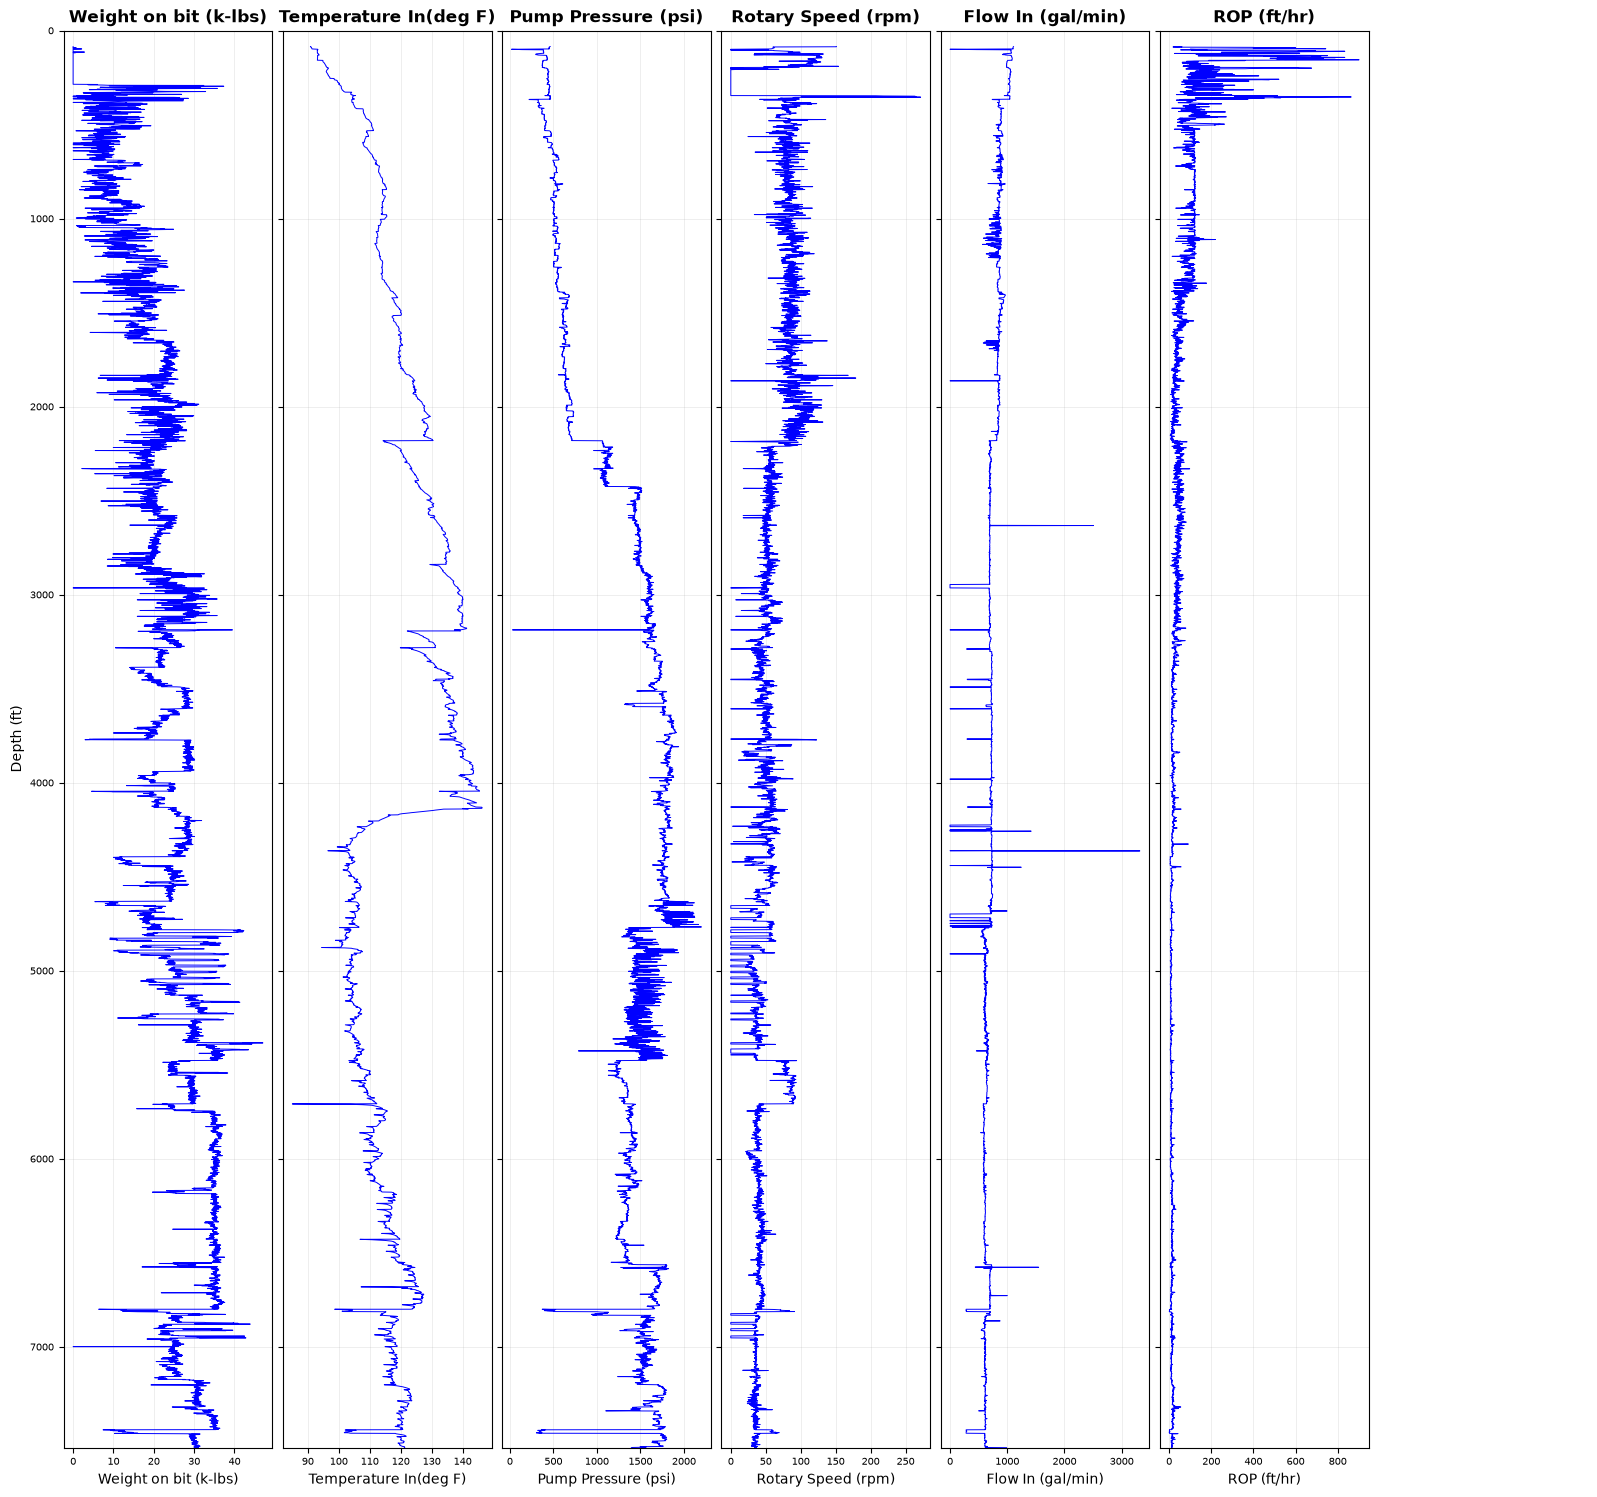

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os



# ============================================================
# 2. COLUMN NAMES
# ============================================================

depth_col = "Depth (ft)"

parameters = [
    'Weight on bit (k-lbs)',
    'Temperature In(deg F)',
    'Pump Pressure (psi)',
    'Rotary Speed (rpm)',
    'Flow In (gal/min)',
    "ROP (ft/hr)"
]

# ============================================================
# 3. CONVERT TO NUMERIC
# ============================================================

df[depth_col] = pd.to_numeric(df[depth_col], errors="coerce")

for col in parameters:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows where depth is missing
df = df.dropna(subset=[depth_col])

# Sort according to depth
df = df.sort_values(depth_col)

# ============================================================
# 4. CREATE COMPACT MULTI-PANEL FIGURE
# ============================================================

# 6 plots in first row + 5 plots in second row
fig, axes = plt.subplots(
    nrows=1,
    ncols=7,
    figsize=(16, 15),
    sharey=True
)

# Flatten axes
axes = axes.flatten()

# ============================================================
# 5. PLOT EACH PARAMETER
# ============================================================

for i, parameter in enumerate(parameters):

    ax = axes[i]

    # Remove missing values
    data = df[[depth_col, parameter]].dropna()

    # Plot
    ax.plot(
        data[parameter],
        data[depth_col],
        color="blue",
        linewidth=0.7
    )

    # Depth increases downward
    ax.set_ylim(df[depth_col].max(), 0)

    # Title
    ax.set_title(
        parameter,
        fontsize=12,
        fontweight="bold"
    )

    # X-axis label
    ax.set_xlabel(
        parameter,
        fontsize=10
    )

    # Y-axis label only for first column
    if i % 6 == 0:
        ax.set_ylabel(
            "Depth (ft)",
            fontsize=10
        )
    else:
        ax.set_ylabel("")

    # Grid
    ax.grid(
        True,
        alpha=0.3,
        linewidth=0.5
    )

    # Tick size
    ax.tick_params(
        axis="both",
        labelsize=7
    )

# ============================================================
# 6. HIDE UNUSED 12th PANEL
# ============================================================

axes[-1].axis("off")

# ============================================================
# 7. IMPROVE SPACING
# ============================================================

plt.tight_layout(
    pad=0.8,
    w_pad=0.4,
    h_pad=1.0
)

# ============================================================
# 8. SAVE FIGURE
# ============================================================

plt.savefig(
    "All_Drilling_Parameters_vs_Depth.png",
    dpi=300,
    bbox_inches="tight"
)

# ============================================================
# 9. DISPLAY
# ============================================================

plt.show()

## Defining the Target Variables and Features

In [8]:
features = [
    'Depth (ft)',
    'Weight on bit (k-lbs)',
    'Temperature In(deg F)',
    'Pump Pressure (psi)',
    'Rotary Speed (rpm)',
    'Flow In (gal/min)',
]

target = 'ROP (ft/hr)'

X = df[features]
Y = df[target]

## Outlier Isolation Algorithm

In [9]:
from sklearn.ensemble import IsolationForest

# User input
contamination = float(
    input("Enter contamination level (e.g. 0.05): ")
)

features = [
    'Depth (ft)',
    'Weight on bit (k-lbs)',
    'Temperature In(deg F)',
    'Pump Pressure (psi)',
    'Rotary Speed (rpm)',
    'Flow In (gal/min)',
]

target = 'ROP (ft/hr)'

X = df[features]
y = df[target]

iso = IsolationForest(
    contamination=contamination,
    n_estimators=500,
    random_state=42
)

labels = iso.fit_predict(X)

mask = labels == 1

X_clean = X[mask]
y_clean = y[mask]

print("Original Rows:", len(X))
print("Remaining Rows:", len(X_clean))
print("Removed Rows:", len(X) - len(X_clean))

Original Rows: 7305
Remaining Rows: 7195
Removed Rows: 110


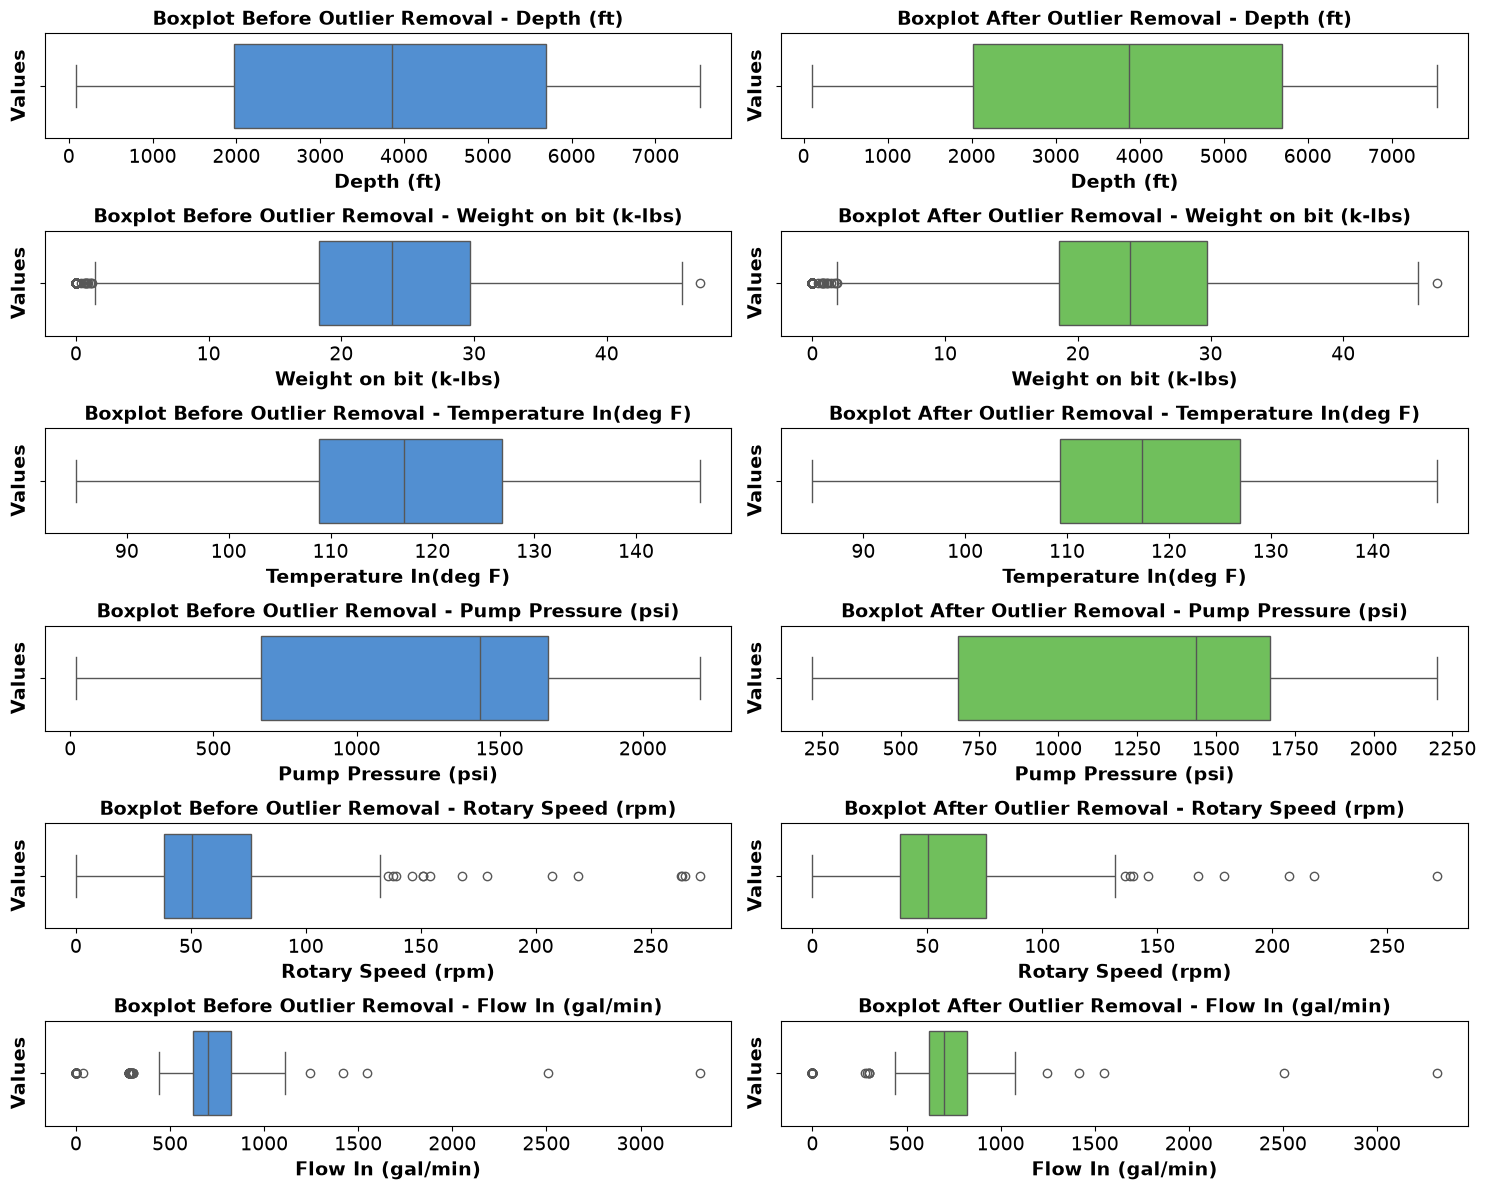

In [10]:

data_no_outliers = df.loc[mask].copy()

# Saving the data without outliers to a new CSV file
data_no_outliers.to_csv('data_no_outliers.csv', index=False)

# Visualize all 11 features side-by-side on a single page
fig, axes = plt.subplots(len(features), 2, figsize=(15, 12))

# Loop through all features
for i, feature in enumerate(features):

    # 1. Left Plot: Before Outlier Removal
    sns.boxplot(x=df[feature], ax=axes[i, 0], color="#3d8ee6")
    axes[i, 0].set_title(
        f'Boxplot Before Outlier Removal - {feature}',
        fontsize=14, weight='bold'
    )
    axes[i, 0].set_xlabel(feature, fontsize=14, weight='bold')
    axes[i, 0].set_ylabel('Values', fontsize=14, weight='bold')
    axes[i, 0].tick_params(labelsize=14)

    # 2. Right Plot: After Outlier Removal
    sns.boxplot(x=data_no_outliers[feature], ax=axes[i, 1], color="#66cf4c")
    axes[i, 1].set_title(
        f'Boxplot After Outlier Removal - {feature}',
        fontsize=14, weight='bold'
    )
    axes[i, 1].set_xlabel(feature, fontsize=14, weight='bold')
    axes[i, 1].set_ylabel('Values', fontsize=14, weight='bold')
    axes[i, 1].tick_params(labelsize=14)

# Ensures proper layout spacing for all 11 feature comparisons
plt.tight_layout()

# Save all plots on a single page
plt.savefig('outlier_comparison.png', dpi=300, bbox_inches='tight')
plt.savefig('outlier_comparison.pdf', bbox_inches='tight')

# Display the complete figure
plt.show()

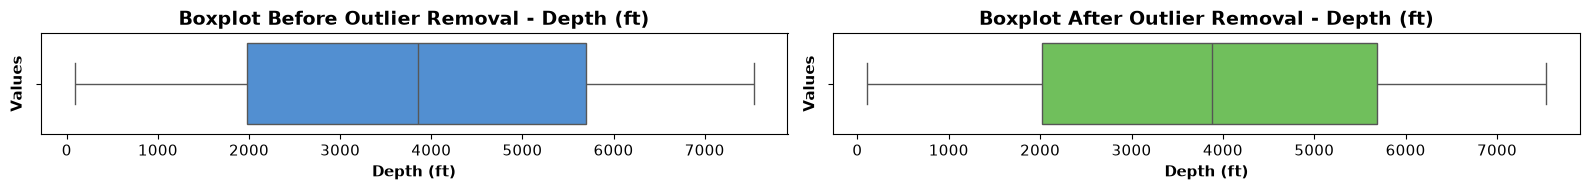

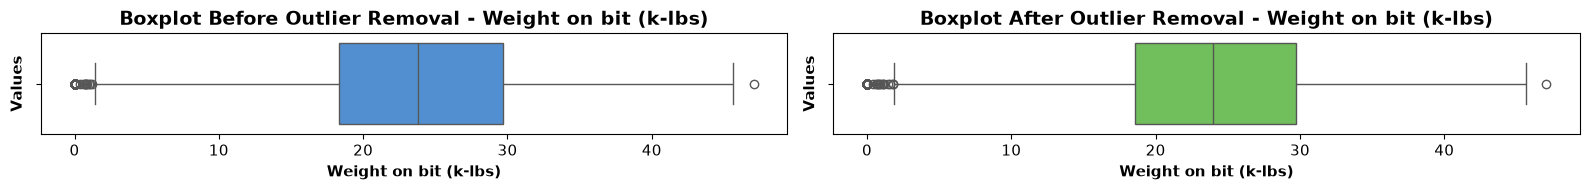

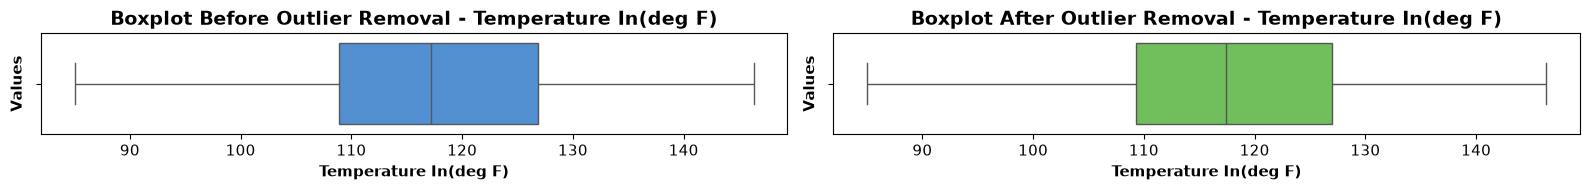

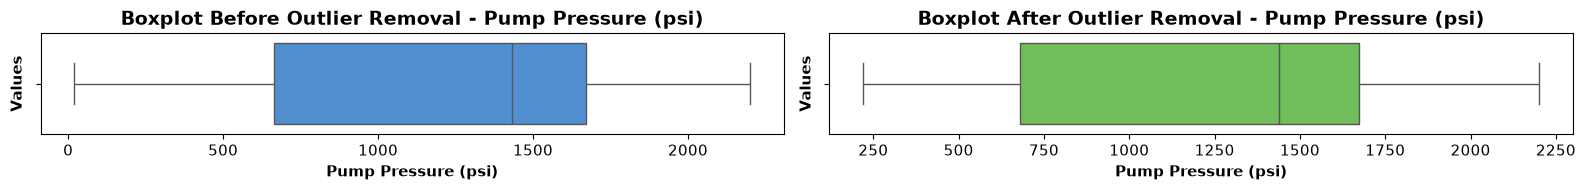

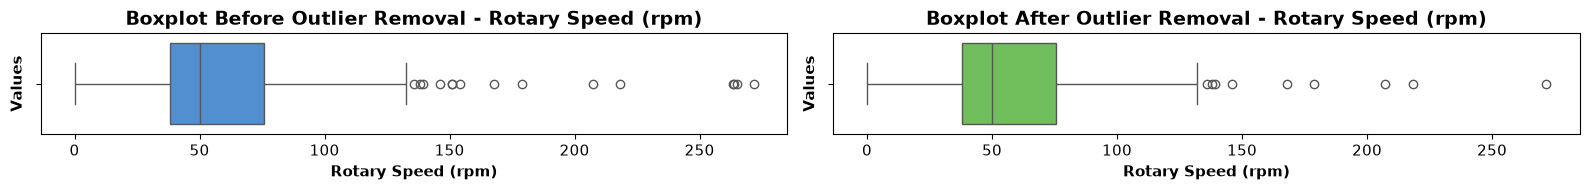

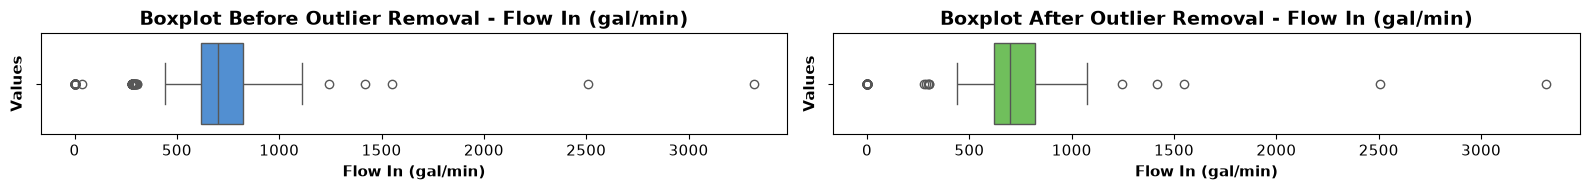

In [11]:
data_no_outliers = df.loc[mask].copy()

# Saving the data without outliers to a new CSV file
data_no_outliers.to_csv('data_no_outliers.csv', index=False) 

# Visualize boxplots side-by-side (1 row, 2 columns per feature)
for feature in features:
    # Set a clean canvas size (16 inches wide, 4 inches tall)
    fig, axes = plt.subplots(1, 2, figsize=(16, 2))
    
    # 1. Left Plot: Before Outlier Removal
    sns.boxplot(x=df[feature], ax=axes[0], color="#3d8ee6")
    axes[0].set_title(f'Boxplot Before Outlier Removal - {feature}', fontsize=14, weight='bold')
    axes[0].set_xlabel(feature, fontsize=11, weight='bold')
    axes[0].set_ylabel('Values', fontsize=11, weight='bold')
    axes[0].tick_params(labelsize=11)

    # 2. Right Plot: After Outlier Removal
    sns.boxplot(x=data_no_outliers[feature], ax=axes[1], color="#66cf4c")
    axes[1].set_title(f'Boxplot After Outlier Removal - {feature}', fontsize=14, weight='bold')
    axes[1].set_xlabel(feature, fontsize=11, weight='bold')
    axes[1].set_ylabel('Values', fontsize=11, weight='bold')
    axes[1].tick_params(labelsize=11)

    # Ensures proper layout spacing and displays the paired row
    plt.tight_layout()
    plt.show()

## After Outlier vs Before Outlier Graphs 

Original data shape: (7305, 12)
After outlier removal: (7195, 12)


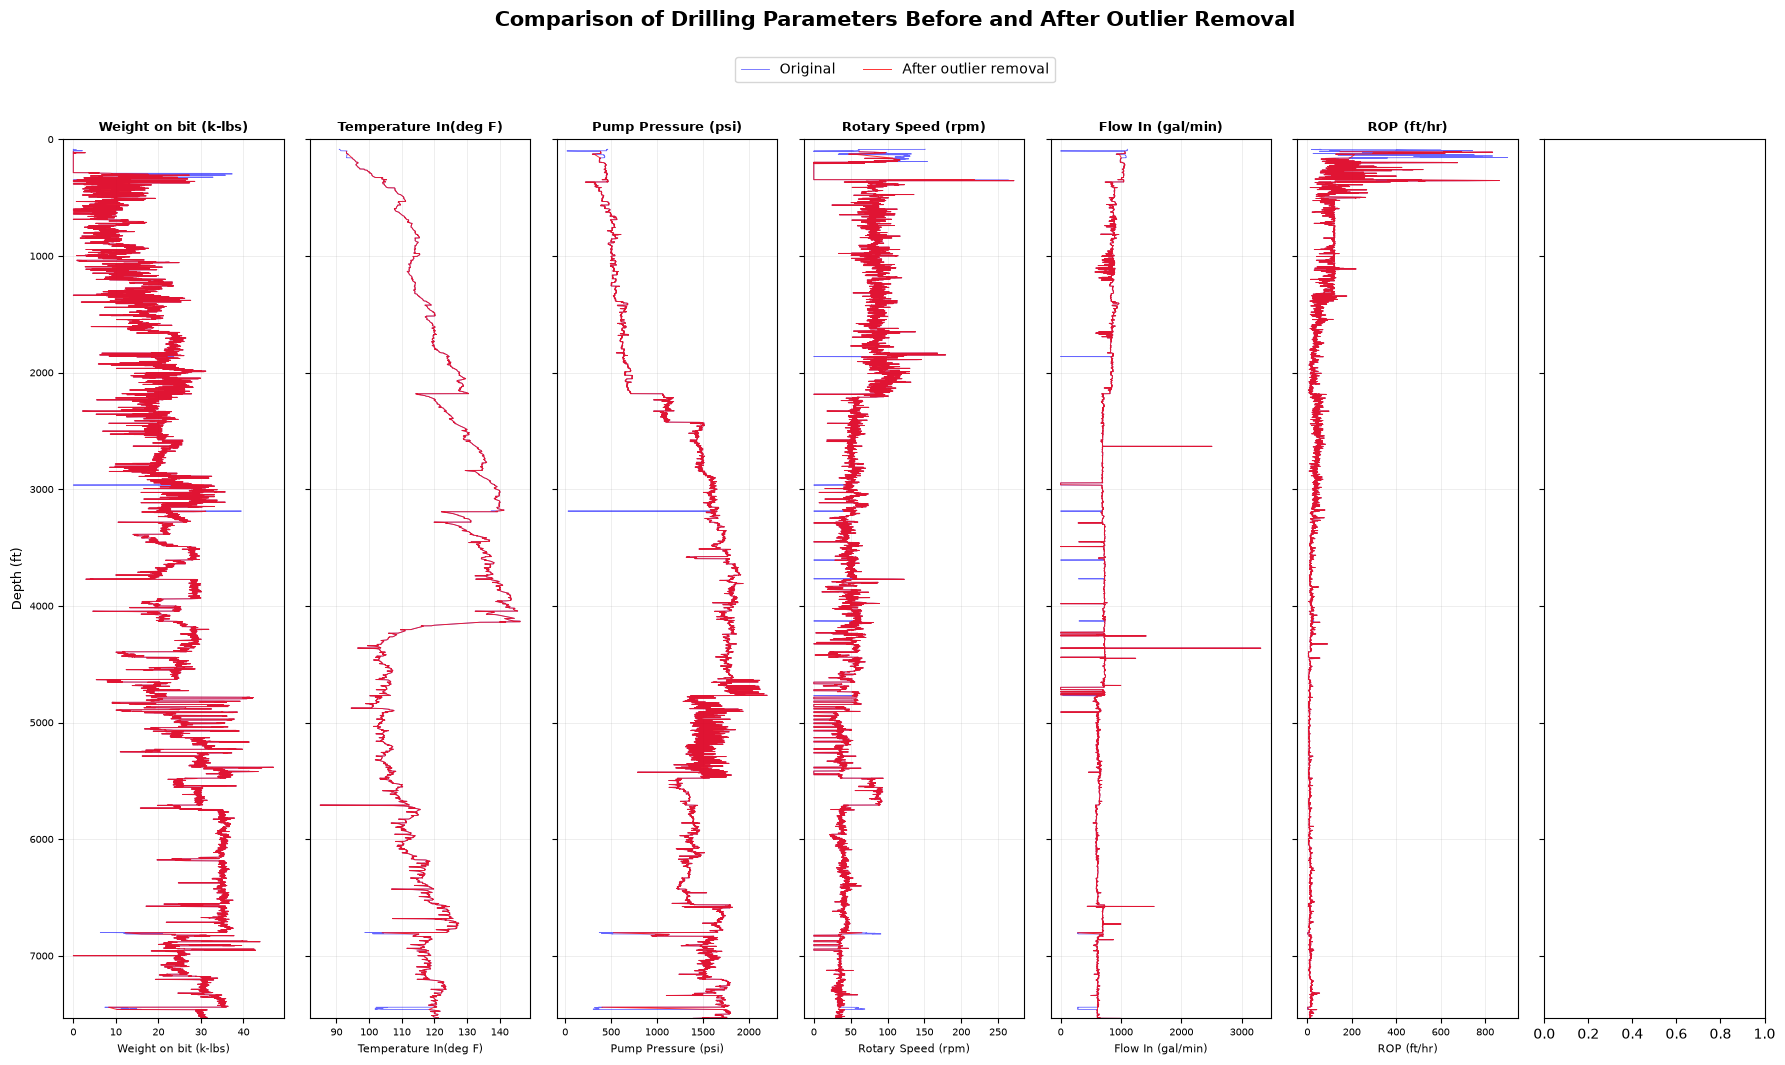


Comparison plot created successfully!
Saved to: Outlier_Comparison_Plots\Original_vs_No_Outlier.png


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ============================================================
# 1. READ BOTH CSV FILES
# ============================================================

original_file = "well.csv"
clean_file = "data_no_outliers.csv"

df_original = pd.read_csv(original_file)
df_clean = pd.read_csv(clean_file)

print("Original data shape:", df_original.shape)
print("After outlier removal:", df_clean.shape)


# ============================================================
# 2. DEFINE COLUMNS
# ============================================================

depth_col = "Depth (ft)"

parameters = [
    'Weight on bit (k-lbs)',
    'Temperature In(deg F)',
    'Pump Pressure (psi)',
    'Rotary Speed (rpm)',
    'Flow In (gal/min)',
    "ROP (ft/hr)"
]


# ============================================================
# 3. CONVERT DATA TO NUMERIC
# ============================================================

for df in [df_original, df_clean]:

    df[depth_col] = pd.to_numeric(
        df[depth_col],
        errors="coerce"
    )

    for col in parameters:

        if col in df.columns:
            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )


# ============================================================
# 4. SORT BY DEPTH
# ============================================================

df_original = df_original.sort_values(depth_col)
df_clean = df_clean.sort_values(depth_col)


# ============================================================
# 5. CREATE OUTPUT FOLDER
# ============================================================

output_folder = "Outlier_Comparison_Plots"

os.makedirs(
    output_folder,
    exist_ok=True
)


# ============================================================
# 6. CREATE 2 × 6 MULTI-PANEL FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    7,
    figsize=(18, 10),
    sharey=True
)

axes = axes.flatten()


# ============================================================
# 7. PLOT ORIGINAL VS NO-OUTLIER DATA
# ============================================================

for i, parameter in enumerate(parameters):

    ax = axes[i]

    # --------------------------------------------------------
    # ORIGINAL DATA
    # --------------------------------------------------------

    original_data = df_original[
        [depth_col, parameter]
    ].dropna()

    ax.plot(
        original_data[parameter],
        original_data[depth_col],
        color="blue",
        linewidth=0.6,
        alpha=0.6,
        label="Original"
    )


    # --------------------------------------------------------
    # DATA AFTER OUTLIER REMOVAL
    # --------------------------------------------------------

    clean_data = df_clean[
        [depth_col, parameter]
    ].dropna()

    ax.plot(
        clean_data[parameter],
        clean_data[depth_col],
        color="red",
        linewidth=0.7,
        alpha=0.8,
        label="After outlier removal"
    )


    # --------------------------------------------------------
    # DEPTH INCREASES DOWNWARD
    # --------------------------------------------------------

    ax.set_ylim(df[depth_col].max(), 0)


    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    ax.set_title(
        parameter,
        fontsize=9,
        fontweight="bold"
    )


    # --------------------------------------------------------
    # X-AXIS LABEL
    # --------------------------------------------------------

    ax.set_xlabel(
        parameter,
        fontsize=8
    )


    # --------------------------------------------------------
    # Y-AXIS LABEL
    # --------------------------------------------------------

    if i % 6 == 0:

        ax.set_ylabel(
            "Depth (ft)",
            fontsize=9
        )

    else:

        ax.set_ylabel("")


    # --------------------------------------------------------
    # GRID
    # --------------------------------------------------------

    ax.grid(
        True,
        alpha=0.3,
        linewidth=0.5
    )


    # --------------------------------------------------------
    # TICK SIZE
    # --------------------------------------------------------

    ax.tick_params(
        axis="both",
        labelsize=7
    )


# ============================================================
# 8. REMOVE EMPTY 12th PANEL
# ============================================================


# ============================================================
# 9. ONE COMMON LEGEND
# ============================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    fontsize=10,
    bbox_to_anchor=(0.5, 1.02)
)


# ============================================================
# 10. MAIN TITLE
# ============================================================

fig.suptitle(
    "Comparison of Drilling Parameters Before and After Outlier Removal",
    fontsize=15,
    fontweight="bold",
    y=1.06
)


# ============================================================
# 11. ADJUST SPACING
# ============================================================

plt.tight_layout(
    w_pad=0.8,
    h_pad=1.5
)


# ============================================================
# 12. SAVE HIGH-RESOLUTION FIGURE
# ============================================================

plt.savefig(
    os.path.join(
        output_folder,
        "Original_vs_No_Outlier.png"
    ),
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# 13. DISPLAY
# ============================================================

plt.show()

plt.close()


print("\nComparison plot created successfully!")
print(
    "Saved to:",
    os.path.join(
        output_folder,
        "Original_vs_No_Outlier.png"
    )
)

## feature Analysis / Coorelation

Pearson Correlation with ROP:
Depth (ft)              -0.6053
Weight on bit (k-lbs)   -0.5967
Pump Pressure (psi)     -0.5958
Flow In (gal/min)        0.5388
Rotary Speed (rpm)       0.2899
Temperature In(deg F)   -0.1932
Name: ROP (ft/hr), dtype: float64


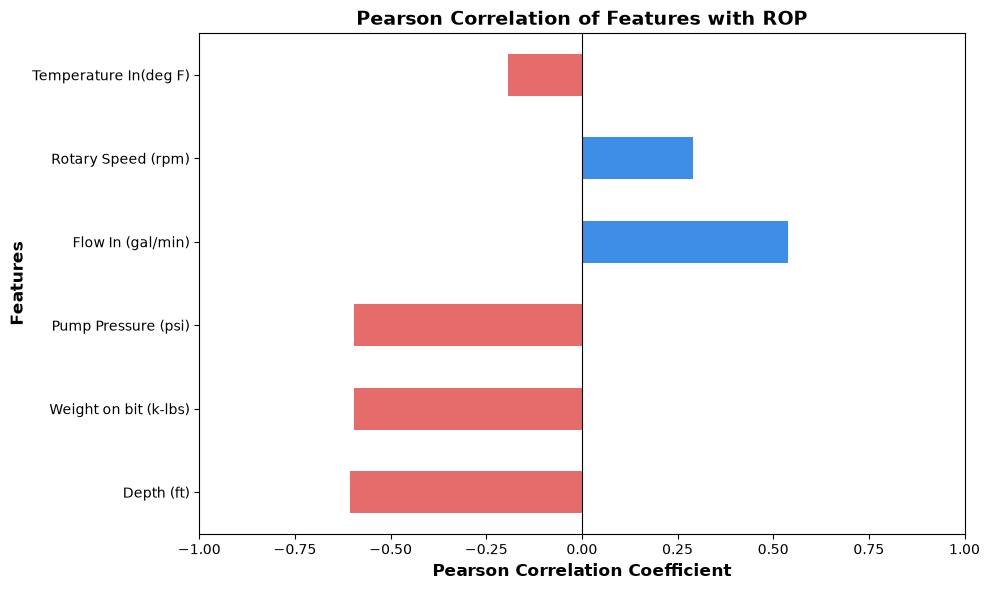

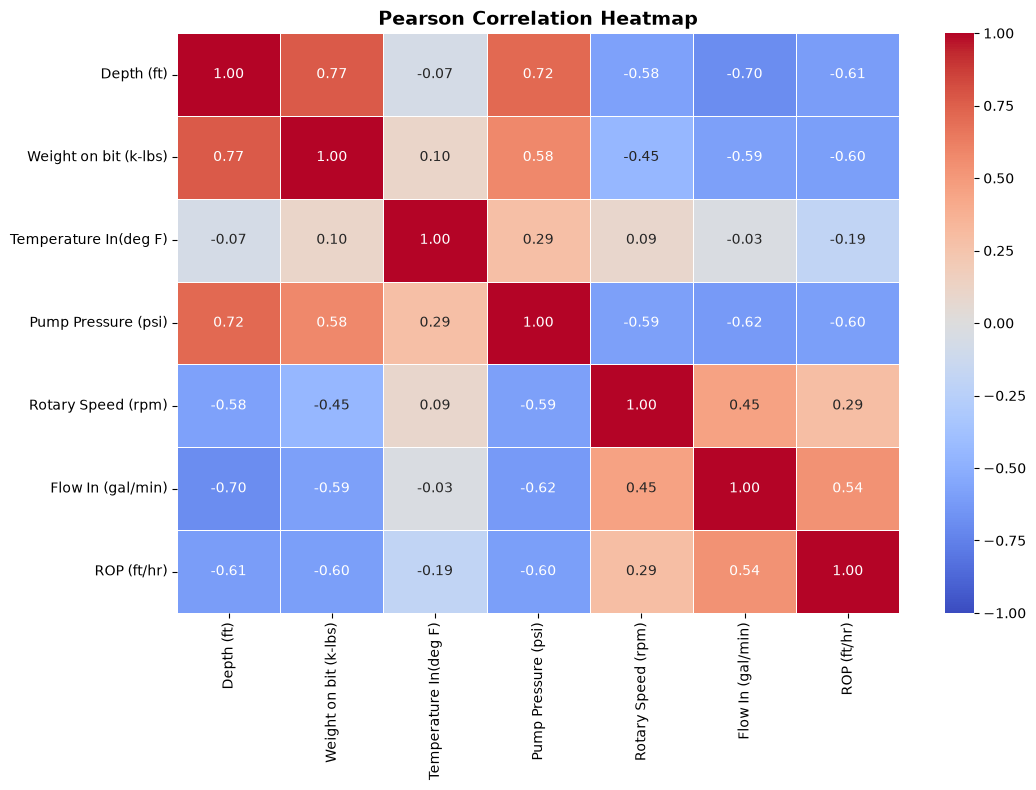

In [13]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    'Depth (ft)',
    'Weight on bit (k-lbs)',
    'Temperature In(deg F)',
    'Pump Pressure (psi)',
    'Rotary Speed (rpm)',
    'Flow In (gal/min)',
]

target = 'ROP (ft/hr)'

# Select features and target
data = df[features + [target]].apply(pd.to_numeric, errors='coerce')

# Pearson correlation matrix
correlation_matrix = data.corr(method='pearson')

# Print correlation of each feature with ROP
rop_correlation = correlation_matrix[target].drop(target)
rop_correlation = rop_correlation.sort_values(
    key=abs, ascending=False
)

print("Pearson Correlation with ROP:")
print(rop_correlation.round(4))

# 1. Bar chart: Feature correlation with ROP
plt.figure(figsize=(10, 6))
colors = [
    '#3d8ee6' if value >= 0 else '#e66b6b'
    for value in rop_correlation
]

rop_correlation.plot(kind='barh', color=colors)
plt.axvline(x=0, color='black', linewidth=0.8)
plt.xlabel('Pearson Correlation Coefficient', fontsize=12,
           fontweight='bold')
plt.ylabel('Features', fontsize=12, fontweight='bold')
plt.title('Pearson Correlation of Features with ROP',
          fontsize=14, fontweight='bold')
plt.xlim(-1, 1)
plt.tight_layout()
plt.show()

# 2. Heatmap: Correlation among all features and ROP
plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f',
    linewidths=0.5
)
plt.title('Pearson Correlation Heatmap',
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## splitting of data into training and testing data

In [14]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

## Scale Data - Very important for KNN as it is distance based algorithm

In [15]:
from sklearn.preprocessing import Normalizer
import pandas as pd

scaler = Normalizer()

X_train_s = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_s = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Original Shape:", X_train.shape)
print("Scaled Shape:", X_train_s.shape)

print(X_train_s.head())

Original Shape: (5844, 6)
Scaled Shape: (5844, 6)
      Depth (ft)  Weight on bit (k-lbs)  Temperature In(deg F)  \
565     0.532970               0.000000               0.086651   
6301    0.976306               0.005620               0.017497   
7036    0.970740               0.004032               0.016484   
640     0.597078               0.004746               0.088717   
6152    0.976911               0.005390               0.017835   

      Pump Pressure (psi)  Rotary Speed (rpm)  Flow In (gal/min)  
565              0.439345            0.082003           0.713223  
6301             0.195804            0.006715           0.090025  
7036             0.225286            0.004990           0.081226  
640              0.401351            0.067550           0.685536  
6152             0.191851            0.006954           0.091882  


## Random Forest  Model Implementation

In [16]:
from sklearn.model_selection import GridSearchCV
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_s, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [17]:
y_pred_rf = rf.predict(X_test_s)

Model Evaluation

In [18]:
r2=r2_score(Y_test, y_pred_rf)
rmse=np.sqrt(mean_squared_error(Y_test, y_pred_rf))
mae=mean_absolute_error(Y_test, y_pred_rf)
mape= np.mean(np.abs((Y_test - y_pred_rf) / Y_test)) * 100
print('R2 =', r2)
print('RMSE =', rmse)
print('MAE =', mae)
print('MAPE =', mape)

R2 = 0.8316156985410825
RMSE = 30.38850471406339
MAE = 9.708204547610004
MAPE = 20.981563337319947


Creating a results dataframe to compare actual and predicted values

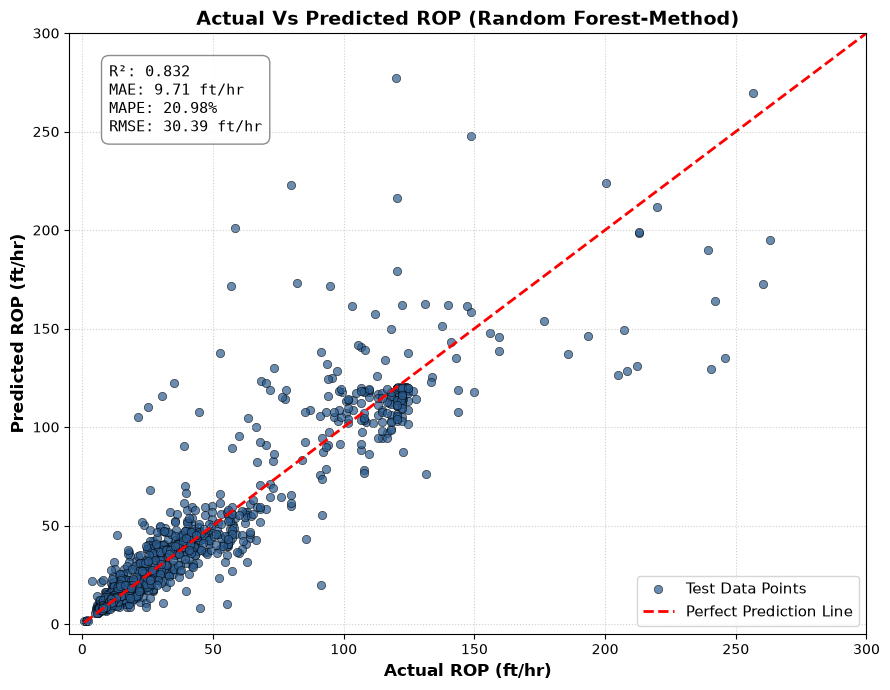

In [19]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Calculate evaluation metrics
r2 = r2_score(Y_test, y_pred_rf)
mae = mean_absolute_error(Y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(Y_test, y_pred_rf))
mape = np.mean(np.abs((Y_test - y_pred_rf) / (Y_test + 1e-10))) * 100

# 2. Plot setup
plt.figure(figsize=(9, 7))  # Made slightly more square for a balanced zoom view
plt.scatter(Y_test, y_pred_rf, alpha=0.7, color='#2b5c8f', edgecolors='k', linewidth=0.5, label="Test Data Points")

plt.xlabel('Actual ROP (ft/hr)', fontsize=12, weight='bold')
plt.ylabel('Predicted ROP (ft/hr)', fontsize=12, weight='bold')
plt.title('Actual Vs Predicted ROP (Random Forest-Method)', fontsize=14, weight='bold')

# 3. Diagonal reference line
min_val = min(min(Y_test), min(y_pred_rf))
max_val = max(max(Y_test), max(y_pred_rf))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label="Perfect Prediction Line") 

# ==========================================
# ULTRA FOCUS AREA LIMITS (Zoomed into 0-150)
# ==========================================
plt.xlim(-5, 300)
plt.ylim(-5, 300)

# Add grid lines to make tracking individual points easier in tight space
plt.grid(True, linestyle=':', alpha=0.6)

# 4. Create string text for metrics box
metrics_box = (
    f"R²: {r2:.3f}\n"
    f"MAE: {mae:.2f} ft/hr\n"
    f"MAPE: {mape:.2f}%\n"
    f"RMSE: {rmse:.2f} ft/hr"
)

# Position changed to 'upper left' but adjusted nicely for the tight window
box_properties = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='gray')
plt.text(0.05, 0.95, metrics_box, transform=plt.gca().transAxes, fontsize=11,
         verticalalignment='top', bbox=box_properties, fontfamily='monospace')

# 5. Display indicators
plt.legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

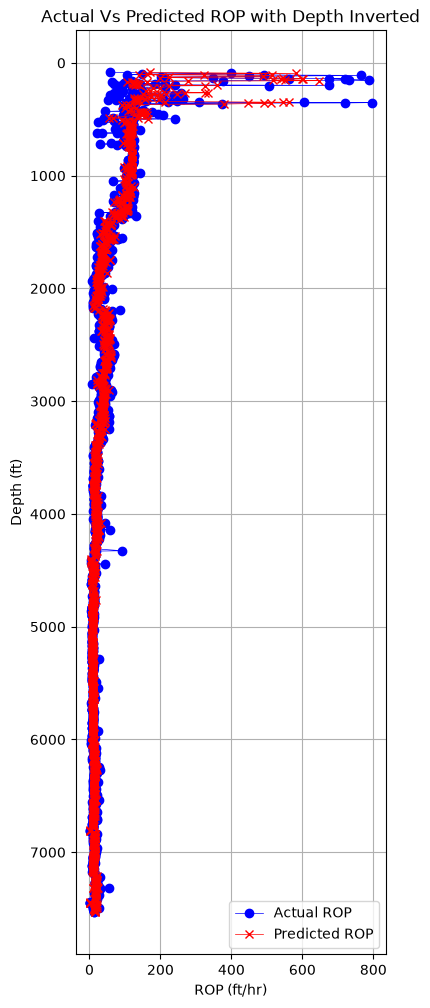

In [20]:
results = X_test.copy()
results['Actual_ROP'] = Y_test
results['Predicted_ROP'] = y_pred_rf

# Sort by depth to see how the model performs at different depths
results = results.sort_values('Depth (ft)')
plt.figure(figsize=(4,12)) 
plt.plot(results['Actual_ROP'],results['Depth (ft)'], label='Actual ROP', color='blue', marker='o', linewidth=0.5)
plt.plot(results['Predicted_ROP'],results['Depth (ft)'], label='Predicted ROP', color='red', marker='x', linewidth=0.5)
plt.gca().invert_yaxis()  # Invert y-axis to have depth increasing downwards
plt.ylabel("Depth (ft)")
plt.xlabel('ROP (ft/hr)')
plt.title('Actual Vs Predicted ROP with Depth Inverted')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

                 Feature  Importance
2  Temperature In(deg F)    0.543505
0             Depth (ft)    0.258439
5      Flow In (gal/min)    0.117281
3    Pump Pressure (psi)    0.036614
4     Rotary Speed (rpm)    0.033462
1  Weight on bit (k-lbs)    0.010698


## SVM 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Model comparison on the same test set:


,Model,R2,RMSE,MAE,MAPE (%)
0,CatBoost,0.833,30.228,10.600,27.530
1,Random Forest,0.832,30.389,9.708,20.982
2,LightGBM,0.826,30.887,10.242,24.738
3,XGBoost,0.817,31.718,10.389,24.244
4,KNN,0.807,32.538,10.033,21.455
5,SVM,0.705,40.201,12.052,25.010


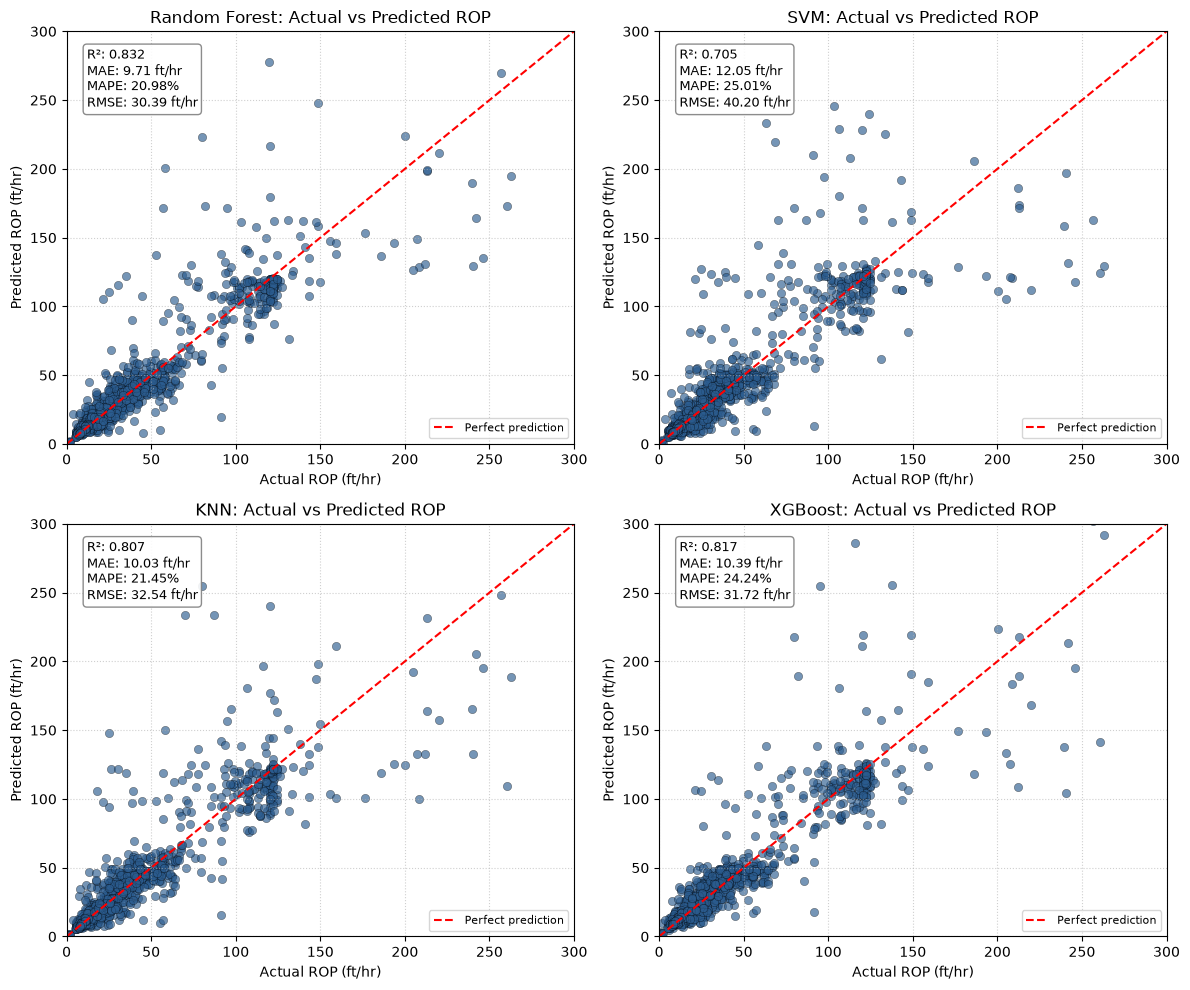

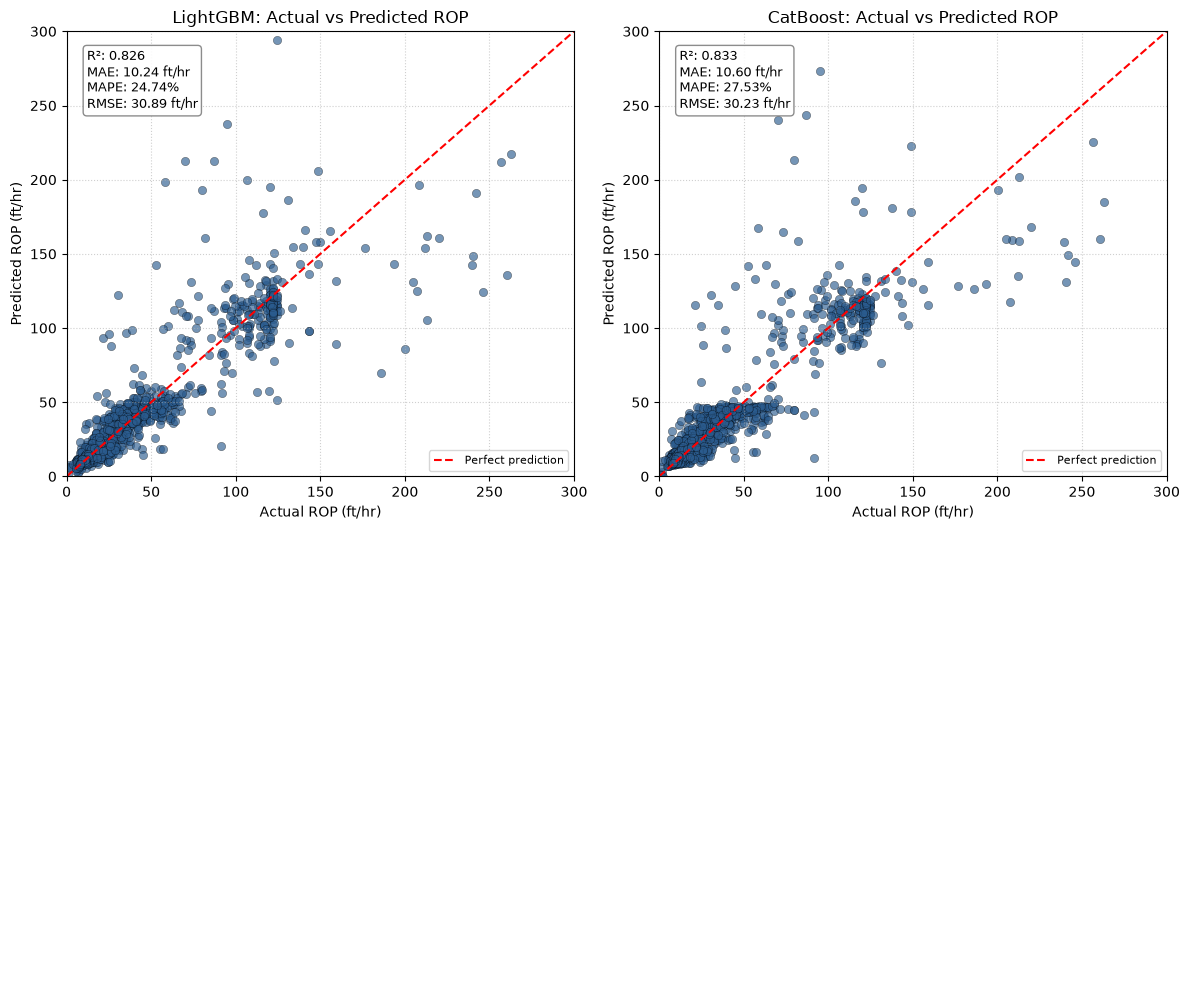

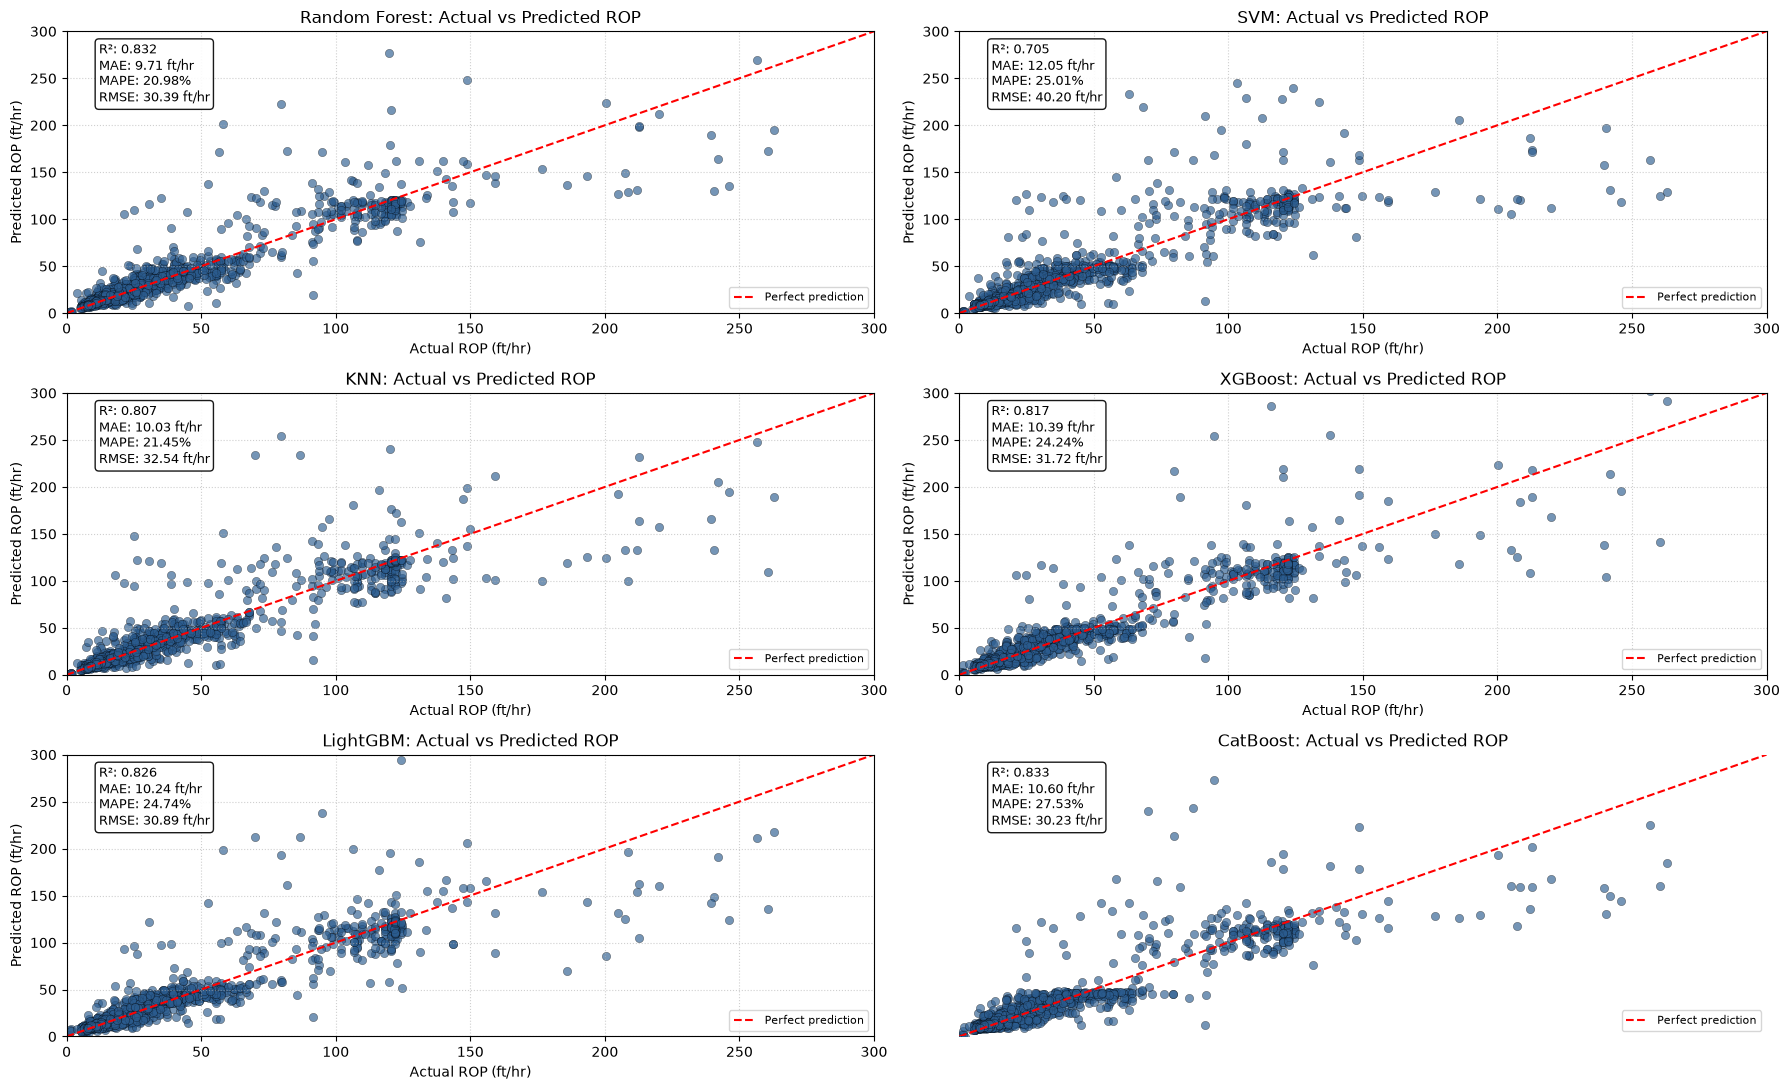

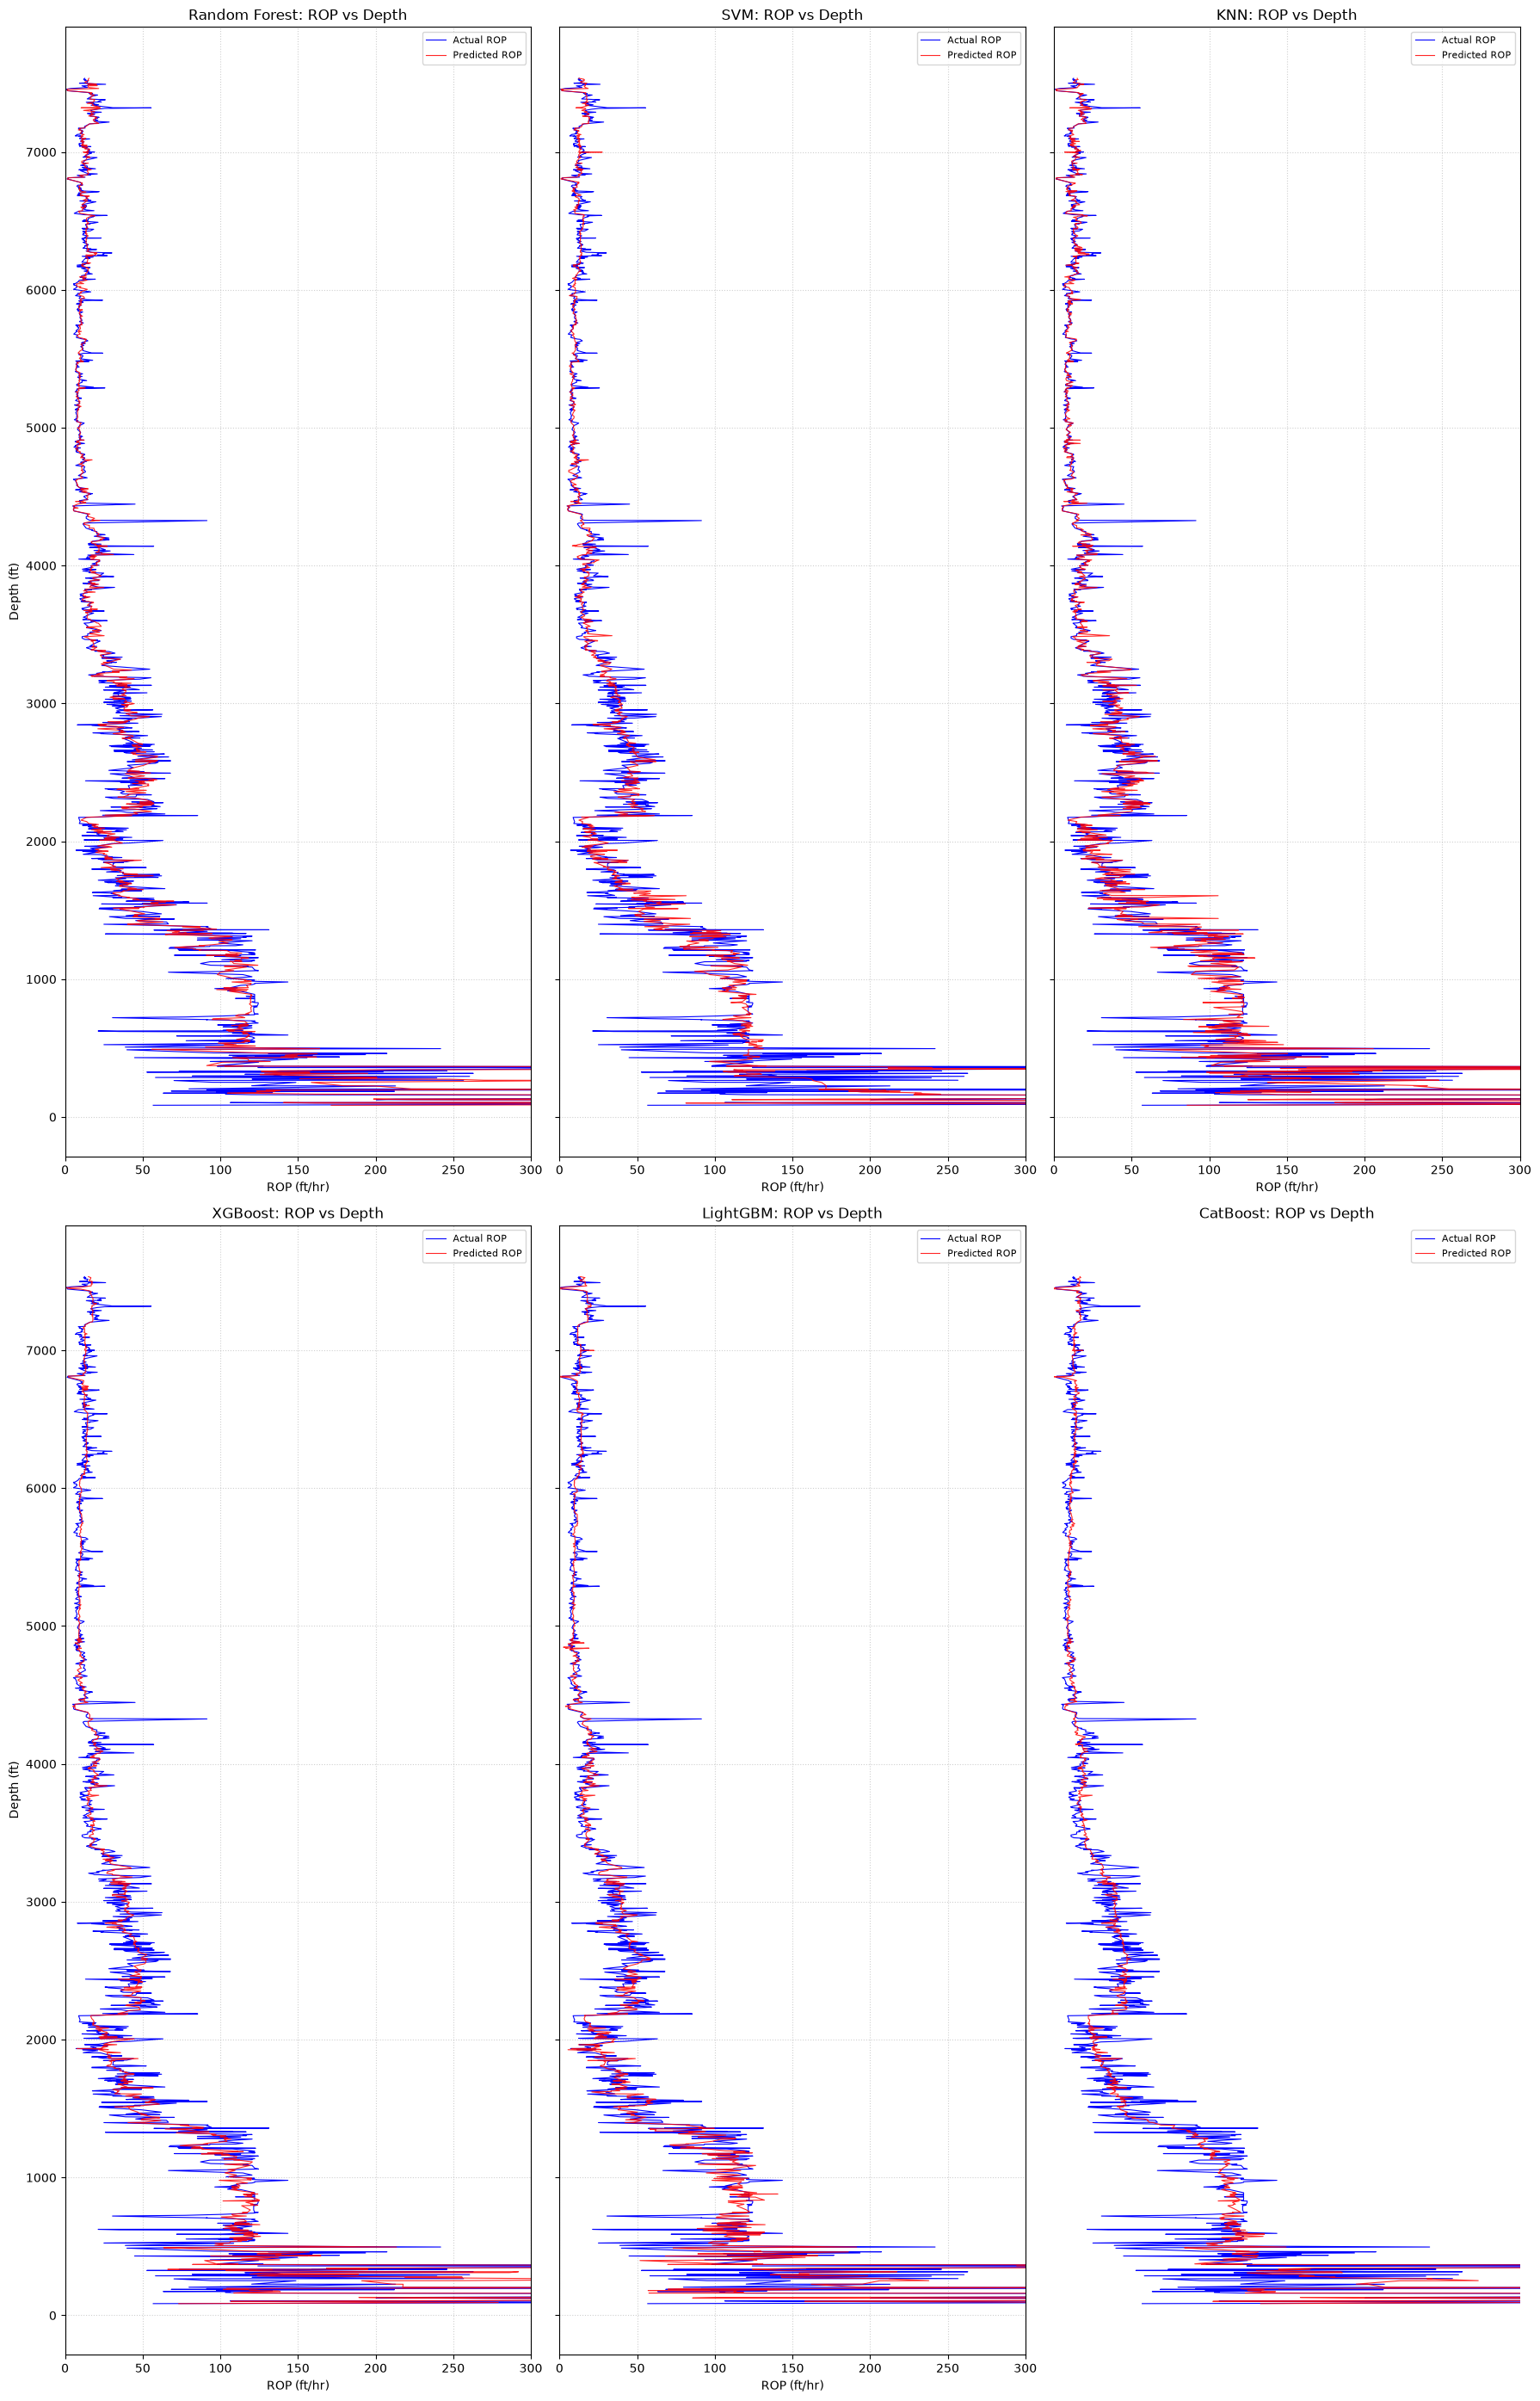

In [25]:
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# If needed, install the additional models:
%pip install xgboost lightgbm catboost


# Use the existing Random Forest model and test split as the baseline.
model_predictions = {
    "Random Forest": rf.predict(X_test_s)
}

# Scale features for distance/kernel-based models.
models_to_fit = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=100, epsilon=0.1)
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5, weights="distance")
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    ),
    "CatBoost": CatBoostRegressor(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )
}

for model_name, model in models_to_fit.items():
    model.fit(X_train, Y_train)
    model_predictions[model_name] = model.predict(X_test)


# Calculate evaluation metrics for every model.
y_true = Y_test.to_numpy()
comparison_rows = []

for model_name, predictions in model_predictions.items():
    predictions = np.asarray(predictions)
    comparison_rows.append({
        "Model": model_name,
        "R2": r2_score(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "MAE": mean_absolute_error(y_true, predictions),
        "MAPE (%)": np.mean(
            np.abs(y_true - predictions) /
            np.maximum(np.abs(y_true), 1e-10)
        ) * 100
    })

comparison_metrics = (
    pd.DataFrame(comparison_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("Model comparison on the same test set:")
display(comparison_metrics.round(3))


# Prepare test results sorted by depth for plotting.
plot_results = X_test[[depth_col]].copy()
plot_results["Actual_ROP"] = Y_test
for model_name, predictions in model_predictions.items():
    plot_results[model_name] = predictions

plot_results = plot_results.sort_values(depth_col)
plot_limit = 300
# Graph 1: individual actual-vs-predicted plots, arranged 2x2.
model_items = list(model_predictions.items())

for start in range(0, len(model_items), 4):
    batch = model_items[start:start + 4]
    fig_scatter, scatter_axes = plt.subplots(2, 2, figsize=(12, 10))
    scatter_axes = scatter_axes.flatten()

    for ax, (model_name, predictions) in zip(scatter_axes, batch):
        predictions = np.asarray(predictions)

        ax.scatter(
            y_true, predictions,
            alpha=0.65,
            color="#2b5c8f",
            edgecolors="k",
            linewidth=0.3
        )
        ax.plot(
            [0, plot_limit], [0, plot_limit],
            "r--", linewidth=1.5, label="Perfect prediction"
        )

        model_row = comparison_metrics.loc[
            comparison_metrics["Model"] == model_name
        ].iloc[0]

        ax.text(
            0.04, 0.96,
            f"R²: {model_row['R2']:.3f}\n"
            f"MAE: {model_row['MAE']:.2f} ft/hr\n"
            f"MAPE: {model_row['MAPE (%)']:.2f}%\n"
            f"RMSE: {model_row['RMSE']:.2f} ft/hr",
            transform=ax.transAxes,
            va="top",
            fontsize=9,
            bbox=dict(
                boxstyle="round",
                facecolor="white",
                edgecolor="gray",
                linewidth=1,
                alpha=0.9
            )
        )

        ax.set(
            title=f"{model_name}: Actual vs Predicted ROP",
            xlabel="Actual ROP (ft/hr)",
            ylabel="Predicted ROP (ft/hr)",
            xlim=(0, plot_limit),
            ylim=(0, plot_limit)
        )
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.legend(loc="lower right", fontsize=8)

    for ax in scatter_axes[len(batch):]:
        ax.axis("off")

    fig_scatter.tight_layout()
    plt.show()

# Graph 1: actual vs. predicted ROP, with a metric summary for each model.
fig_scatter, scatter_axes = plt.subplots(3, 2, figsize=(18, 11))
scatter_axes = scatter_axes.flatten()

for ax, (model_name, predictions) in zip(
    scatter_axes, model_predictions.items()
):
    predictions = np.asarray(predictions)

    ax.scatter(
        y_true, predictions,
        alpha=0.65,
        color="#2b5c8f",
        edgecolors="k",
        linewidth=0.3
    )
    ax.plot(
        [0, plot_limit], [0, plot_limit],
        "r--", linewidth=1.5, label="Perfect prediction"
    )

    model_row = comparison_metrics.loc[
        comparison_metrics["Model"] == model_name
    ].iloc[0]

    ax.text(
        0.04, 0.96,
        f"R²: {model_row['R2']:.3f}\n"
        f"MAE: {model_row['MAE']:.2f} ft/hr\n"
        f"MAPE: {model_row['MAPE (%)']:.2f}%\n"
        f"RMSE: {model_row['RMSE']:.2f} ft/hr",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9)
    )

    ax.set(
        title=f"{model_name}: Actual vs Predicted ROP",
        xlabel="Actual ROP (ft/hr)",
        ylabel="Predicted ROP (ft/hr)",
        xlim=(0, plot_limit),
        ylim=(0, plot_limit)
    )
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="lower right", fontsize=8)

scatter_axes[-1].axis("off")
fig_scatter.tight_layout()
plt.show()


# Graph 2: actual and predicted ROP versus depth.
fig_depth, depth_axes = plt.subplots(2, 3, figsize=(18, 28), sharey=True)
depth_axes = depth_axes.flatten()

for ax, model_name in zip(depth_axes, model_predictions):
    ax.plot(
        plot_results["Actual_ROP"],
        plot_results[depth_col],
        color="blue",
        linewidth=0.8,
        label="Actual ROP"
    )
    ax.plot(
        plot_results[model_name],
        plot_results[depth_col],
        color="red",
        linewidth=0.8,
        alpha=0.85,
        label="Predicted ROP"
    )

    ax.set(
        title=f"{model_name}: ROP vs Depth",
        xlabel="ROP (ft/hr)",
        xlim=(0, plot_limit)
    )
    ax.invert_yaxis()
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=8)

for ax in depth_axes[::3]:
    ax.set_ylabel("Depth (ft)")

depth_axes[-1].axis("off")
fig_depth.tight_layout()
plt.show()

## Hyperparameter Tuning and Baseline Comparison

Tuning Random Forest: 8 randomized settings, 3-fold CV
  Best CV RMSE: 29.7240
Tuning SVM: 8 randomized settings, 3-fold CV
  Best CV RMSE: 35.3530
Tuning KNN: 8 randomized settings, 3-fold CV
  Best CV RMSE: 32.9945
Tuning XGBoost: 8 randomized settings, 3-fold CV
  Best CV RMSE: 30.5358
Tuning LightGBM: 8 randomized settings, 3-fold CV
  Best CV RMSE: 30.7074
Tuning CatBoost: 8 randomized settings, 3-fold CV
  Best CV RMSE: 29.6389

Cross-validation tuning summary (CV used training rows only):


,Model,Best CV RMSE,Best parameters,Search time (s)
0,Random Forest,29.723954,"{'n_estimators': 200, 'min_samples_split': 5, ...",5.108739
1,SVM,35.352950,"{'svr__gamma': 'auto', 'svr__epsilon': 0.2, 's...",13.702523
2,KNN,32.994469,"{'kneighborsregressor__weights': 'distance', '...",0.608299
3,XGBoost,30.535838,"{'subsample': 0.7, 'n_estimators': 300, 'min_c...",2.841435
4,LightGBM,30.707418,"{'num_leaves': 63, 'n_estimators': 300, 'min_c...",2.743786
5,CatBoost,29.638867,"{'learning_rate': 0.05, 'l2_leaf_reg': 9, 'ite...",6.799660


Held-out test comparison (baseline vs tuned on identical test rows):


,Model,Version,R2,RMSE,MAE,MAPE (%)
0,CatBoost,Tuned,0.8392,29.6978,10.6679,28.3407
1,KNN,Tuned,0.8385,29.7652,9.4601,20.2896
2,CatBoost,Baseline,0.8334,30.2280,10.5999,27.5298
3,Random Forest,Baseline,0.8316,30.3885,9.7082,20.9816
4,Random Forest,Tuned,0.8282,30.6993,9.6736,21.0795
5,LightGBM,Baseline,0.8260,30.8871,10.2423,24.7384
6,XGBoost,Tuned,0.8250,30.9769,10.1000,23.4897
7,XGBoost,Baseline,0.8166,31.7181,10.3891,24.2437
8,LightGBM,Tuned,0.8120,32.1115,10.3274,22.2492
9,KNN,Baseline,0.8070,32.5378,10.0330,21.4546


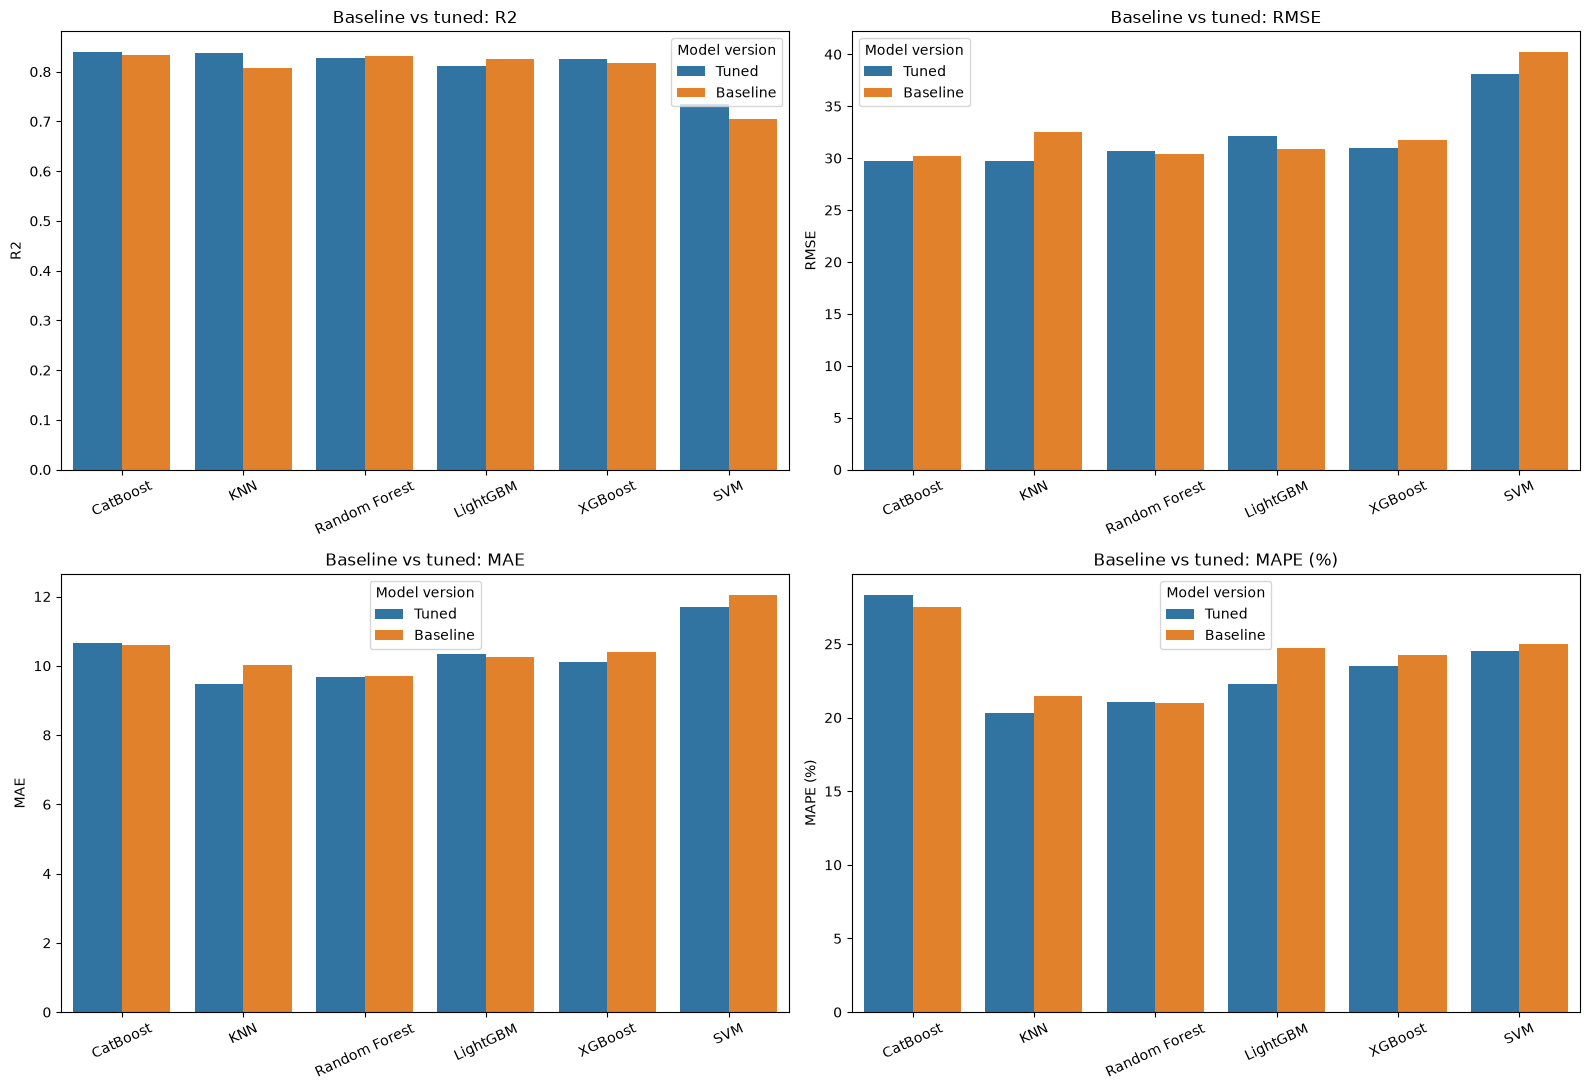

Lowest test RMSE: CatBoost (Tuned) ? R2=0.8392, RMSE=29.6978, MAE=10.6679


In [23]:
# Tune all six benchmark models with randomized 3-fold CV on training data only.
# The held-out test data is reserved for the final baseline-versus-tuned comparison.
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import time

random_state = 42
cv_folds = 3
search_iterations = 8
search_configs = {
    "Random Forest": (
        RandomForestRegressor(random_state=random_state, n_jobs=-1),
        {"n_estimators": [200, 300, 500], "max_depth": [10, 15, 20, None],
         "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4],
         "max_features": [1.0, "sqrt"]}, X_train_s, X_test_s),
    "SVM": (
        make_pipeline(StandardScaler(), SVR(kernel="rbf")),
        {"svr__C": [1, 10, 50, 100, 200], "svr__epsilon": [0.05, 0.1, 0.2, 0.5],
         "svr__gamma": ["scale", "auto"]}, X_train, X_test),
    "KNN": (
        make_pipeline(StandardScaler(), KNeighborsRegressor(n_jobs=-1)),
        {"kneighborsregressor__n_neighbors": [3, 5, 7, 9, 13, 17],
         "kneighborsregressor__weights": ["uniform", "distance"],
         "kneighborsregressor__p": [1, 2]}, X_train, X_test),
    "XGBoost": (
        XGBRegressor(objective="reg:squarederror", random_state=random_state, n_jobs=-1, verbosity=0),
        {"n_estimators": [200, 300, 500], "max_depth": [3, 4, 6, 8],
         "learning_rate": [0.03, 0.05, 0.1], "subsample": [0.7, 0.85, 1.0],
         "colsample_bytree": [0.7, 0.85, 1.0], "min_child_weight": [1, 3, 5]}, X_train, X_test),
    "LightGBM": (
        LGBMRegressor(random_state=random_state, n_jobs=-1, verbosity=-1),
        {"n_estimators": [200, 300, 500], "learning_rate": [0.03, 0.05, 0.1],
         "num_leaves": [15, 31, 63], "max_depth": [-1, 8, 12],
         "min_child_samples": [10, 20, 30], "colsample_bytree": [0.7, 0.85, 1.0]}, X_train, X_test),
    "CatBoost": (
        CatBoostRegressor(loss_function="RMSE", random_seed=random_state, verbose=False,
                          allow_writing_files=False, thread_count=-1),
        {"iterations": [200, 300, 500], "depth": [4, 6, 8],
         "learning_rate": [0.03, 0.05, 0.1], "l2_leaf_reg": [3, 5, 9]}, X_train, X_test),
}

actual_test = np.asarray(Y_test, dtype=float)
tuned_models, tuned_predictions, tuning_rows = {}, {}, []
for model_name, (estimator, parameter_space, train_features, test_features) in search_configs.items():
    print(f"Tuning {model_name}: {search_iterations} randomized settings, {cv_folds}-fold CV", flush=True)
    started = time.perf_counter()
    search = RandomizedSearchCV(
        estimator=estimator, param_distributions=parameter_space,
        n_iter=search_iterations, scoring="neg_root_mean_squared_error",
        cv=cv_folds, random_state=random_state, n_jobs=1, refit=True,
        return_train_score=False,
    )
    search.fit(train_features, Y_train)
    tuned_models[model_name] = search.best_estimator_
    tuned_predictions[model_name] = np.asarray(search.best_estimator_.predict(test_features), dtype=float)
    tuning_rows.append({
        "Model": model_name, "Best CV RMSE": -search.best_score_,
        "Best parameters": search.best_params_, "Search time (s)": time.perf_counter() - started,
    })
    print(f"  Best CV RMSE: {-search.best_score_:.4f}", flush=True)

comparison_rows = []
for model_name, baseline_prediction in model_predictions.items():
    for version, prediction in [("Baseline", baseline_prediction), ("Tuned", tuned_predictions[model_name])]:
        prediction = np.asarray(prediction, dtype=float)
        comparison_rows.append({
            "Model": model_name, "Version": version,
            "R2": r2_score(actual_test, prediction),
            "RMSE": np.sqrt(mean_squared_error(actual_test, prediction)),
            "MAE": mean_absolute_error(actual_test, prediction),
            "MAPE (%)": np.mean(np.abs(actual_test - prediction) /
                                 np.maximum(np.abs(actual_test), 1e-10)) * 100,
        })

tuned_comparison = pd.DataFrame(comparison_rows).sort_values(
    ["RMSE", "MAE"], ascending=True
).reset_index(drop=True)
tuning_summary = pd.DataFrame(tuning_rows)
print("\nCross-validation tuning summary (CV used training rows only):")
display(tuning_summary)
print("Held-out test comparison (baseline vs tuned on identical test rows):")
display(tuned_comparison.round(4))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, metric in zip(axes.flat, ["R2", "RMSE", "MAE", "MAPE (%)"]):
    sns.barplot(data=tuned_comparison, x="Model", y=metric, hue="Version", ax=ax)
    ax.set_title(f"Baseline vs tuned: {metric}")
    ax.tick_params(axis="x", rotation=25)
    ax.set_xlabel("")
    ax.legend(title="Model version")
fig.tight_layout()
plt.show()

best_test_result = tuned_comparison.iloc[0]
print(f"Lowest test RMSE: {best_test_result['Model']} ({best_test_result['Version']}) ? "
      f"R2={best_test_result['R2']:.4f}, RMSE={best_test_result['RMSE']:.4f}, "
      f"MAE={best_test_result['MAE']:.4f}")

## ANN Model: 3 Hidden Layers x 12 Neurons

ANN hidden-layer architecture: (12, 12, 12)
Training rows: 5844 | test rows: 1461
Training iterations: 754 | final training loss: 446.305292
ANN Test R2 = 0.7618
ANN Test RMSE = 36.1464 ft/hr
ANN Test MAE = 12.1642 ft/hr
ANN Test MAPE = 31.37%


,Model,R2,RMSE,MAE,MAPE (%)
0,ANN (3 x 12),0.7618,36.1464,12.1642,31.3667


ANN compared with saved baseline/tuned models on the same held-out split:


,Model,Version,R2,RMSE,MAE,MAPE (%)
0,CatBoost,Tuned,0.8392,29.6978,10.6679,28.3407
1,KNN,Tuned,0.8385,29.7652,9.4601,20.2896
2,CatBoost,Baseline,0.8334,30.2280,10.5999,27.5298
3,Random Forest,Baseline,0.8316,30.3885,9.7082,20.9816
4,Random Forest,Tuned,0.8282,30.6993,9.6736,21.0795
5,LightGBM,Baseline,0.8260,30.8871,10.2423,24.7384
6,XGBoost,Tuned,0.8250,30.9769,10.1000,23.4897
7,XGBoost,Baseline,0.8166,31.7181,10.3891,24.2437
8,LightGBM,Tuned,0.8120,32.1115,10.3274,22.2492
9,KNN,Baseline,0.8070,32.5378,10.0330,21.4546


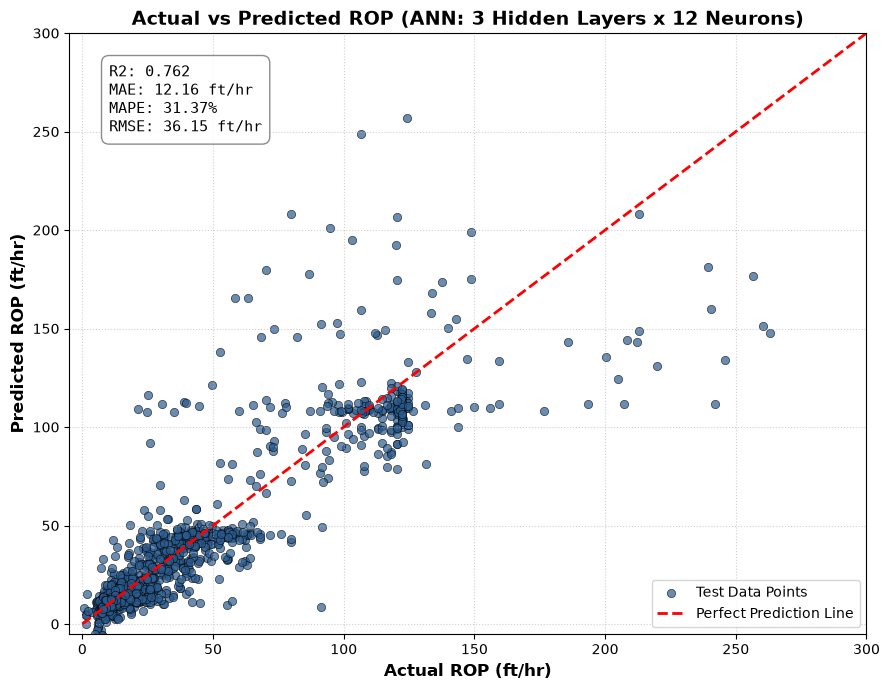

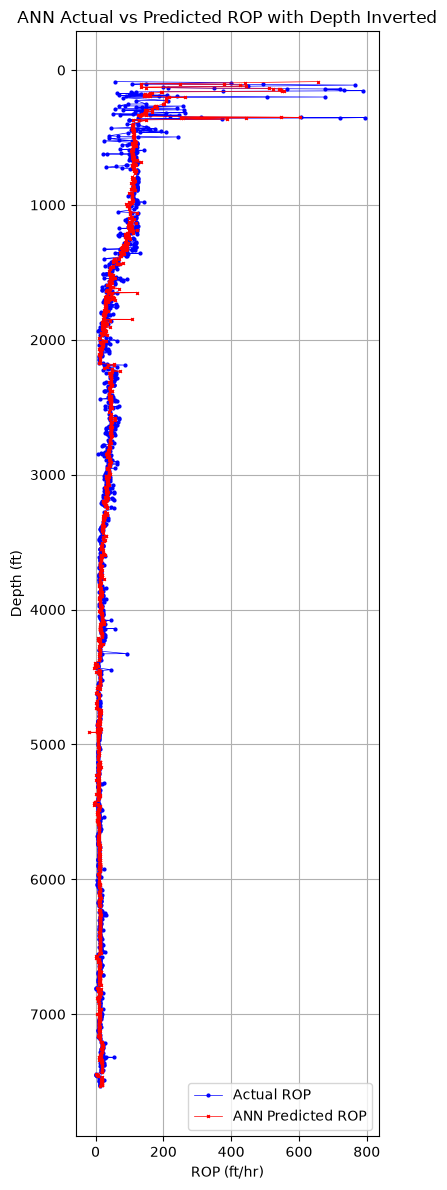

In [24]:
# Artificial Neural Network (ANN) with the requested 3 hidden layers x 12 neurons.
# Uses the existing notebook train/test split when available; otherwise recreates the
# same 80/20 split (random_state=42) from well.csv for standalone execution.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

ANN_HIDDEN_LAYERS = (12, 12, 12)
ANN_RANDOM_STATE = 42

if not all(name in globals() for name in ("X_train", "X_test", "Y_train", "Y_test")):
    data_path = Path("well.csv")
    if not data_path.is_file():
        data_path = Path(r"C:\Users\Mahesh_004\Desktop\2nd paper work\well.csv")
    if not data_path.is_file():
        raise FileNotFoundError(f"well.csv not found in {Path.cwd()} or the project folder.")
    ann_features = [
        "Depth (ft)", "Weight on bit (k-lbs)", "Temperature In(deg F)",
        "Pump Pressure (psi)", "Rotary Speed (rpm)", "Flow In (gal/min)",
    ]
    ann_target = "ROP (ft/hr)"
    ann_data = pd.read_csv(data_path)
    ann_X = ann_data[ann_features].apply(pd.to_numeric, errors="coerce")
    ann_y = pd.to_numeric(ann_data[ann_target], errors="coerce")
    ann_valid = ann_X.notna().all(axis=1) & ann_y.notna()
    ann_X, ann_y = ann_X.loc[ann_valid], ann_y.loc[ann_valid]
    X_train, X_test, Y_train, Y_test = train_test_split(
        ann_X, ann_y, test_size=0.20, random_state=ANN_RANDOM_STATE
    )

# Standardization is fit only on training data through the pipeline.
ann_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=ANN_HIDDEN_LAYERS,
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        max_iter=1500,
        early_stopping=True,
        n_iter_no_change=30,
        random_state=ANN_RANDOM_STATE,
    ),
)
ann_model.fit(X_train, Y_train)
ann_prediction = np.asarray(ann_model.predict(X_test), dtype=float).reshape(-1)
ann_actual = np.asarray(Y_test, dtype=float).reshape(-1)
ann_r2 = r2_score(ann_actual, ann_prediction)
ann_rmse = np.sqrt(mean_squared_error(ann_actual, ann_prediction))
ann_mae = mean_absolute_error(ann_actual, ann_prediction)
ann_mape = np.mean(
    np.abs(ann_actual - ann_prediction) / np.maximum(np.abs(ann_actual), 1e-10)
) * 100
ann_mlp = ann_model.named_steps["mlpregressor"]
print("ANN hidden-layer architecture:", ANN_HIDDEN_LAYERS)
print("Training rows:", len(X_train), "| test rows:", len(X_test))
print("Training iterations:", ann_mlp.n_iter_, "| final training loss:", round(ann_mlp.loss_, 6))
if ann_mlp.n_iter_ >= ann_mlp.max_iter:
    print("Convergence note: max_iter was reached; consider increasing it if a convergence warning was reported.")
print(f"ANN Test R2 = {ann_r2:.4f}")
print(f"ANN Test RMSE = {ann_rmse:.4f} ft/hr")
print(f"ANN Test MAE = {ann_mae:.4f} ft/hr")
print(f"ANN Test MAPE = {ann_mape:.2f}%")

ann_metrics = pd.DataFrame([{
    "Model": "ANN (3 x 12)", "R2": ann_r2, "RMSE": ann_rmse,
    "MAE": ann_mae, "MAPE (%)": ann_mape,
}])
display(ann_metrics.round(4))

# Add this ANN result to the notebook's saved model comparison when available.
if "tuned_comparison" in globals() and isinstance(tuned_comparison, pd.DataFrame):
    ann_reference = tuned_comparison.copy()
else:
    # Saved held-out comparison from the six-model section, for standalone ANN execution.
    ann_reference = pd.DataFrame([
        ("CatBoost", "Tuned", .8392, 29.6978, 10.6679, 28.3407),
        ("KNN", "Tuned", .8385, 29.7652, 9.4601, 20.2896),
        ("CatBoost", "Baseline", .8334, 30.2280, 10.5999, 27.5298),
        ("Random Forest", "Baseline", .8316, 30.3885, 9.7082, 20.9816),
        ("Random Forest", "Tuned", .8282, 30.6993, 9.6736, 21.0795),
        ("LightGBM", "Baseline", .8260, 30.8871, 10.2423, 24.7384),
        ("XGBoost", "Tuned", .8250, 30.9769, 10.1000, 23.4897),
        ("XGBoost", "Baseline", .8166, 31.7181, 10.3891, 24.2437),
        ("LightGBM", "Tuned", .8120, 32.1115, 10.3274, 22.2492),
        ("KNN", "Baseline", .8070, 32.5378, 10.0330, 21.4546),
        ("SVM", "Tuned", .7355, 38.0832, 11.7069, 24.5199),
        ("SVM", "Baseline", .7053, 40.2010, 12.0521, 25.0096),
    ], columns=["Model", "Version", "R2", "RMSE", "MAE", "MAPE (%)"])
ann_comparison = pd.concat([
    ann_reference,
    pd.DataFrame([{
        "Model": "ANN (3 x 12)", "Version": "ANN",
        "R2": ann_r2, "RMSE": ann_rmse, "MAE": ann_mae, "MAPE (%)": ann_mape,
    }]),
], ignore_index=True).sort_values(["RMSE", "MAE"]).reset_index(drop=True)
print("ANN compared with saved baseline/tuned models on the same held-out split:")
display(ann_comparison.round(4))

# Plot 1: match the existing actual-versus-predicted Random Forest figure style.
plt.figure(figsize=(9, 7))
plt.scatter(
    ann_actual, ann_prediction, alpha=0.7, color="#2b5c8f",
    edgecolors="k", linewidth=0.5, label="Test Data Points",
)
line_max = max(float(np.max(ann_actual)), float(np.max(ann_prediction)))
plt.plot([0, line_max], [0, line_max], "r--", linewidth=2, label="Perfect Prediction Line")
plt.xlim(-5, 300)
plt.ylim(-5, 300)
plt.xlabel("Actual ROP (ft/hr)", fontsize=12, weight="bold")
plt.ylabel("Predicted ROP (ft/hr)", fontsize=12, weight="bold")
plt.title("Actual vs Predicted ROP (ANN: 3 Hidden Layers x 12 Neurons)", fontsize=14, weight="bold")
plt.grid(True, linestyle=":", alpha=0.6)
ann_metrics_box = (
    f"R2: {ann_r2:.3f}\nMAE: {ann_mae:.2f} ft/hr\n"
    f"MAPE: {ann_mape:.2f}%\nRMSE: {ann_rmse:.2f} ft/hr"
)
plt.text(
    0.05, 0.95, ann_metrics_box, transform=plt.gca().transAxes,
    fontsize=11, verticalalignment="top", fontfamily="monospace",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9, edgecolor="gray"),
)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

# Plot 2: ROP track versus depth, with depth increasing downward.
ann_depth_col = "Depth (ft)"
ann_plot = pd.DataFrame({
    ann_depth_col: X_test[ann_depth_col].to_numpy(),
    "Actual_ROP": ann_actual,
    "Predicted_ROP": ann_prediction,
}).sort_values(ann_depth_col)
plt.figure(figsize=(4, 12))
plt.plot(ann_plot["Actual_ROP"], ann_plot[ann_depth_col], label="Actual ROP", color="blue", marker="o", linewidth=0.5, markersize=2)
plt.plot(ann_plot["Predicted_ROP"], ann_plot[ann_depth_col], label="ANN Predicted ROP", color="red", marker="x", linewidth=0.5, markersize=2)
plt.gca().invert_yaxis()
plt.ylabel("Depth (ft)")
plt.xlabel("ROP (ft/hr)")
plt.title("ANN Actual vs Predicted ROP with Depth Inverted")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
